# REFIT washing-machine project: end-to-end notebook

This notebook runs the **whole analysis from the supplied REFIT data in one place**:

1. **Raw-data cleaning** of House 1 (inspection, duplicates, DST, impossible values, 1-minute resampling, gaps)
2. **Preparing the official cleaned data** for the washing-machine houses (1-minute cache)
3. **Washing-machine EDA** (cycle detection, availability, usage patterns, cross-house comparison, sensitivity)
4. **Disaggregation model**: features, baselines, LightGBM (two-stage), **predictions** and **evaluation** (house split + time split), failure cases

The code is the same as the scripts in `src/` (`python run_all.py` gives identical tables); here it is laid out
cell by cell with the reasoning in between.

**How to run:** put the REFIT data in `data/` (`data/REFIT_RAW_081116/`, `data/CLEAN_REFIT_081116/`,
`data/CLEAN_READ_ME_081116.txt`), open this notebook from the project root, and choose *Run All* (about 11 minutes on a laptop). Every table is written to
`outputs/tables/` and every figure to `outputs/figures/`, and they are shown below as the notebook runs.

## 0. Setup: imports, paths and every threshold in one place

In [1]:
import time
import types
from pathlib import Path

import lightgbm as lgb
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

pd.set_option("display.width", 200, "display.max_columns", 40)

**Configuration.** All paths, the washing-machine channel per house (from the REFIT readme; House 4 has two
washing machines and House 12 has none, so both are excluded), and every threshold used later. Keeping them
in one cell means one change propagates to cleaning, EDA, the model and the numbers in the docs.

In [2]:
# ---------------------------------------------------------------- paths
import os
ROOT = Path.cwd()  # run this notebook from the project root
# REFIT_DATA_DIR lets the data live outside the project (optional)
DATA_DIR = Path(os.environ.get("REFIT_DATA_DIR", ROOT / "data"))  # optional override
RAW_DIR = DATA_DIR / "REFIT_RAW_081116"
CLEAN_DIR = DATA_DIR / "CLEAN_REFIT_081116"
README_TXT = DATA_DIR / "CLEAN_READ_ME_081116.txt"
CACHE_DIR = ROOT / "data" / "cache"

OUT_DIR = ROOT / "outputs"
FIG_DIR = OUT_DIR / "figures"
TAB_DIR = OUT_DIR / "tables"

APPLIANCE_COLS = [f"Appliance{i}" for i in range(1, 10)]
POWER_COLS = ["Aggregate"] + APPLIANCE_COLS


def raw_files(house: int) -> list[Path]:
    """Raw CSVs for a house (Part1, Part2), in order."""
    return sorted(RAW_DIR.glob(f"RAW_House{house}_Part*.csv"))


def clean_file(house: int) -> Path:
    return CLEAN_DIR / f"CLEAN_House{house}.csv"


def check_data_available() -> None:
    """Fail fast with a clear message if the data drive is not mounted."""
    missing = [p for p in (RAW_DIR, CLEAN_DIR, README_TXT) if not p.exists()]
    if missing:
        raise FileNotFoundError(
            "REFIT data not found (external drive disconnected?): "
            + ", ".join(str(p) for p in missing)
        )


def ensure_output_dirs() -> None:
    for d in (CACHE_DIR, FIG_DIR, TAB_DIR):
        d.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------- washing-machine channels
# From CLEAN_READ_ME_081116.txt. House 4 (two washing machines) and
# House 12 (none) are excluded; House 14 does not exist in REFIT.
WM_CHANNEL = {
    1: "Appliance5", 2: "Appliance2", 3: "Appliance6", 5: "Appliance3",
    6: "Appliance2", 7: "Appliance5", 8: "Appliance4", 9: "Appliance3",
    10: "Appliance5", 11: "Appliance3", 13: "Appliance3", 15: "Appliance3",
    16: "Appliance5", 17: "Appliance4", 18: "Appliance5", 19: "Appliance2",
    20: "Appliance4", 21: "Appliance3",
}

# ------------------------------------------------- Phase 1: raw cleaning
RAW_HOUSE = 1
RAW_PLOT_APPLIANCES = ["Appliance1", "Appliance5"]  # fridge, washing machine
MAX_AGGREGATE_W = 23_000   # ~100 A single-phase UK supply at 230 V
MAX_APPLIANCE_W = 4_000    # above any single plug-in appliance (13 A ~ 3 kW)
# Per-appliance plausibility limits for raw House 1 (appliance list from the
# REFIT readme). Readings above them are almost all bit errors: exact powers of
# two (1024, 2048, 3072 W) or a power of two added to a normal reading
# (e.g. 1024 + 79 = 1103 W on the fridge). See DATA.md.
APPLIANCE_LIMIT_W = {
    "Appliance1": 1_000,   # fridge: compressor ~100 W, defrost heater well below 1 kW
    "Appliance2": 1_000,   # freezer (1)
    "Appliance3": 1_000,   # freezer (2)
    "Appliance4": 3_000,   # washer-dryer: ~2.5 kW heater + motor
    "Appliance5": 3_000,   # washing machine: ~2.2 kW heater + motor
    "Appliance6": 3_000,   # dishwasher: ~2.3 kW heater
    "Appliance7": 500,     # computer site
    "Appliance8": 500,     # television site
    "Appliance9": 2_500,   # electric heater (2 kW model)
}
FILL_PART2_GAPS_FROM_PART1 = True  # use Part1 minutes where Part2 is missing (overlap window)
RESAMPLE_RULE = "1min"
MAX_INTERP_GAP_MIN = 5     # gaps <= this are linearly interpolated
# longer gaps stay NaN and are flagged as outages

# ------------------------------------------------- Phase 2: cleaned data
# CLEAN files carry true UTC Unix time (verified against House 1 raw, which is
# local wall-clock); convert to local time for hour/day-of-week analysis.
LOCAL_TZ = "Europe/London"

# ------------------------------------------------- Phase 3: cycle detection
WM_ON_W = 20               # minute is "active" if mean WM power > this
CYCLE_MERGE_GAP_MIN = 10   # pauses shorter than this join one cycle
CYCLE_MIN_DURATION_MIN = 10
CYCLE_MIN_ENERGY_WH = 50
SENSITIVITY_ON_W = [5, 10, 20, 50, 100]
SENSITIVITY_MERGE_MIN = [0, 5, 10, 20, 30]

# ------------------------------------------------- house selection
# Chosen from outputs/tables/clean_wm_houses_availability.csv:
#   3, 5 excluded (most Issues / WM>aggregate minutes), 13 (22.6 % outage),
#   11 (shortest record, months without use).
# Test houses are never used in EDA or tuning.
TRAIN_HOUSES = [2, 7, 10, 15]
VAL_HOUSES = [9]
TEST_HOUSES = [8, 17]
EDA_HOUSES = [1, 2, 7, 9, 10, 15]
EDA_EXAMPLE_HOUSE = 2      # house used for the single-day / single-cycle plots
UK_PEAK_HOURS = range(16, 20)  # 16:00-19:59 weekday evening network peak

# ------------------------------------------------- Phase 4: model
RANDOM_SEED = 42
WINDOW_MIN = 60            # half-width (minutes) of aggregate context window
TIME_SPLIT_FRAC = 0.8      # within-house split: first 80 % train, last 20 % test
EMBARGO_DAYS = 1           # dropped after the split point (> window width)
PRED_ON_GRID_W = [10, 20, 30, 50, 75, 100, 150, 200]  # tuned on validation house
LGBM_PARAMS = dict(
    objective="regression", learning_rate=0.05, num_leaves=63,
    min_child_samples=200, feature_fraction=0.8, bagging_fraction=0.8,
    bagging_freq=1, lambda_l2=1.0, n_estimators=600, verbose=-1,
)

In [3]:
# Collect the configuration in a namespace `C`, so the code below reads like the scripts (C.WM_ON_W, ...)
C = types.SimpleNamespace(**{k: v for k, v in dict(globals()).items()
                            if k.isupper() or k in ("raw_files", "clean_file",
                                                    "check_data_available", "ensure_output_dirs")})
C.check_data_available()   # stops with a clear message if the data folder is missing
C.ensure_output_dirs()


def display_table(name, n=None):
    df = pd.read_csv(C.TAB_DIR / f"{name}.csv")
    print(f"outputs/tables/{name}.csv")
    display(df if n is None else df.head(n))


def show_fig(name):
    print(f"outputs/figures/{name}.png")
    display(Image(filename=str(C.FIG_DIR / f"{name}.png")))

T0 = time.time()
print("data:", C.DATA_DIR)

data: I:\Documents\flock-energy-assignment\data


---
## 1. Raw-data cleaning: House 1

**Goal:** turn the raw House 1 logs (two overlapping CSV files, ~8.5 M rows, readings every 6–8 s) into a
clean 1-minute table, and record every decision.

**Rules and why:**

| Step | Rule | Why |
|---|---|---|
| Time | `Unix` is the authoritative clock | instruction; `Time` agrees within 1 s. Raw `Unix` is UK *local* time (it jumps at DST) |
| Overlap | Part2 is the primary source for 27 Jun – 1 Oct 2014; minutes with no Part2 reading are filled from Part1 | same meter logged twice; averaging both would blur the signal, but Part1 is a valid reading of the same meter where Part2 has nothing |
| Autumn DST | drop 01:00–02:00 on the last Sunday of October | that hour occurs twice and the copies cannot be separated in Part2 |
| Duplicates | first non-missing value per channel | same as "keep first" for complete rows; keeps appliance readings in Part2's split rows |
| Impossible values | aggregate ≤ 0 or > 23 kW; each appliance above its own limit (fridge/freezers 1 kW, computer/TV 0.5 kW, heater 2.5 kW, washer/dishwasher 3 kW) → missing, per channel | ~100 A supply limit; readings above the appliance limits are almost all bit errors (1024, 2048, 3072 W, or a power of two plus a normal reading) |
| Resample | 1-minute means | sensors are not synchronised; 1 min is ample for a 30–120 min wash |
| Gaps | interpolate ≤ 5 min; longer gaps stay missing and are flagged as outages | 5 min cannot invent or hide a wash; filling hours would be invented data |

In [4]:
H = C.RAW_HOUSE
TAG = f"raw_h{H}"

In [5]:
# ------------------------------------------------------------- inspection
def load_part(path):
    df = pd.read_csv(path)
    t = pd.to_datetime(df["Time"], errors="coerce")
    tu = pd.to_datetime(df["Unix"], unit="s")
    info = {
        "file": path.name,
        "rows": len(df),
        "start": tu.min(), "end": tu.max(),
        "unparseable_Time": int(t.isna().sum()),
        "Time_minus_Unix_max_abs_s": float((t - tu).dt.total_seconds().abs().max()),
        "backward_steps": int((np.diff(df["Unix"].values) < 0).sum()),
        "duplicate_Unix_rows": int(df["Unix"].duplicated().sum()),
        "fully_duplicated_rows": int(df.duplicated().sum()),
        "missing_cells": int(df[C.POWER_COLS].isna().sum().sum()),
        "rows_with_any_missing": int(df[C.POWER_COLS].isna().any(axis=1).sum()),
    }
    dup = df.loc[df["Unix"].duplicated(keep=False), ["Unix"] + C.POWER_COLS]
    n_distinct = dup.groupby("Unix")[C.POWER_COLS].nunique().max(axis=1)
    info["duplicate_Unix_groups"] = int(len(n_distinct))
    info["duplicate_groups_conflicting_values"] = int((n_distinct > 1).sum())
    dt = np.diff(np.sort(df["Unix"].unique()))
    info.update({
        "median_interval_s": float(np.median(dt)),
        "pct_interval_5_to_10s": round(100 * float(((dt >= 5) & (dt <= 10)).mean()), 2),
        "gaps_gt_1min": int((dt > 60).sum()),
        "gaps_gt_5min": int((dt > 300).sum()),
        "gaps_gt_1h": int((dt > 3600).sum()),
        "longest_gap_h": round(float(dt.max()) / 3600, 1),
        "aggregate_gt_max": int((df["Aggregate"] > C.MAX_AGGREGATE_W).sum()),
        "aggregate_le_0": int((df["Aggregate"] <= 0).sum()),
        "appliance_gt_max": int((df[C.APPLIANCE_COLS] > C.MAX_APPLIANCE_W).sum().sum()),
        "negative_values": int((df[C.POWER_COLS] < 0).sum().sum()),
    })
    df["part"] = path.stem.rsplit("_", 1)[-1]
    return df.drop(columns="Time"), info

In [6]:
def overlap_alignment(p1, p2):
    """Correlate Part1 vs Part2 1-min aggregate in their overlap at 0 / +-1 h
    shifts: tells whether the parts are the same meter on the same clock."""
    def agg_1min(d):
        s = d.groupby("Unix")["Aggregate"].first()
        s.index = pd.to_datetime(s.index, unit="s")
        return s.resample("1min").mean()
    a, b = agg_1min(p1), agg_1min(p2)
    lo, hi = b.index.min(), a.index.max()
    rows = []
    for h in (-1, 0, 1):
        bs = b.copy()
        bs.index = bs.index + pd.Timedelta(hours=h)
        j = pd.concat([a[lo:hi], bs[lo:hi]], axis=1).dropna()
        rows.append({"part2_shift_h": h, "minutes": len(j),
                     "corr": round(j.corr().iloc[0, 1], 3),
                     "MAE_W": round((j.iloc[:, 0] - j.iloc[:, 1]).abs().mean(), 1)})
    return pd.DataFrame(rows)

In [7]:
def extreme_value_table(df):
    rows = []
    for c in C.POWER_COLS:
        lim = C.MAX_AGGREGATE_W if c == "Aggregate" else C.MAX_APPLIANCE_W
        bad = df.loc[df[c] > lim, c]
        row = {"channel": c, "limit_W": lim, "n_above": len(bad), "max_W": df[c].max(),
               "most_common_bad_values": bad.value_counts().head(4).to_dict()}
        if c != "Aggregate":
            # readings between the per-appliance limit and the general limit
            plim = appliance_limit(c)
            mid = df.loc[(df[c] > plim) & (df[c] <= lim), c]
            pow2 = mid.isin([256 * k for k in range(1, 17)]).mean() if len(mid) else 0.0
            row.update({"appliance_limit_W": plim, "n_between_limits": len(mid),
                        "share_exact_multiple_of_256": round(pow2, 2),
                        "most_common_between_limits": mid.value_counts().head(4).to_dict()})
        rows.append(row)
    return pd.DataFrame(rows)

In [8]:
# ---------------------------------------------------------------- cleaning
def autumn_dst_hours(years):
    """[01:00, 02:00) local on the last Sunday of October - occurs twice."""
    out = []
    for y in years:
        d = pd.Timestamp(f"{y}-10-31")
        d -= pd.Timedelta(days=(d.dayofweek + 1) % 7)
        out.append((d + pd.Timedelta(hours=1), d + pd.Timedelta(hours=2)))
    return out

In [9]:
def fill_short_gaps(s, max_len):
    """Interpolate NaN runs of length <= max_len; return (filled, outage_mask)."""
    na = s.isna()
    run_len = na.groupby((~na).cumsum()).transform("sum")
    short = na & (run_len <= max_len)
    interp = s.interpolate(method="time", limit_area="inside")
    out = s.where(~short, interp)
    return out, out.isna()

In [10]:
def appliance_limit(c):
    return C.APPLIANCE_LIMIT_W.get(c, C.MAX_APPLIANCE_W)

In [11]:
def to_minutes(df, dst_hours):
    """DST drop, de-duplication, impossible values and 1-min means for one
    stream of raw rows. Returns (1-min frame, counts for the log)."""
    ts = pd.to_datetime(df["Unix"], unit="s")
    amb = np.zeros(len(df), bool)
    for a, b in dst_hours:
        amb |= ((ts >= a) & (ts < b)).values
    df = df[~amb]
    n_dst = len(df)
    df = df.sort_values("Unix", kind="mergesort")       # stable: keeps file order
    df = df.groupby("Unix", sort=True)[C.POWER_COLS].first()  # first non-NaN per channel
    n_dedup = len(df)
    n_bad, n_bad_4kw = 0, 0
    for c in C.POWER_COLS:
        if c == "Aggregate":
            bad = (df[c] <= 0) | (df[c] > C.MAX_AGGREGATE_W)
            n_bad_4kw += int(bad.sum())
        else:
            bad = df[c] > appliance_limit(c)
            n_bad_4kw += int((df[c] > C.MAX_APPLIANCE_W).sum())
        n_bad += int(bad.sum())
        df.loc[bad, c] = np.nan
    df.index = pd.to_datetime(df.index, unit="s")
    return df.resample(C.RESAMPLE_RULE).mean(), (n_dst, n_dedup, n_bad, n_bad_4kw)

In [12]:
def clean(parts):
    log = []
    p1, p2 = parts
    log.append(("loaded (Part1 + Part2)", len(p1) + len(p2)))

    t_split = p2["Unix"].min()
    p1_overlap = p1[p1["Unix"] >= t_split]
    p1 = p1[p1["Unix"] < t_split]
    df = pd.concat([p1, p2], ignore_index=True)
    log.append(("Part1 rows inside Part2 window set aside", len(df)))

    ts = pd.to_datetime(df["Unix"], unit="s")
    years = range(ts.min().year, ts.max().year + 1)
    dst_hours = autumn_dst_hours(years)
    m, (n_dst, n_dedup, n_bad, n_general) = to_minutes(df, dst_hours)
    log.append(("ambiguous autumn-DST hour removed", n_dst))
    log.append(("duplicate timestamps merged (keep first)", n_dedup))
    log.append(("impossible values set to NaN (cells)", n_bad))
    log.append(("  of which caught by the general limits (aggregate, appliance > 4 kW)", n_general))
    log.append(("  of which caught only by a per-appliance limit", n_bad - n_general))
    log.append(("1-min grid rows", len(m)))

    # Part2 is the primary source in the overlap window; where it has no
    # reading for a minute, use Part1's reading of the same meter.
    from_p1 = pd.DataFrame(False, index=m.index, columns=C.POWER_COLS)
    if C.FILL_PART2_GAPS_FROM_PART1 and len(p1_overlap):
        m1, _ = to_minutes(p1_overlap, dst_hours)
        m1 = m1.reindex(m.index)
        from_p1 = m.isna() & m1.notna()
        m = m.where(~from_p1, m1)
    log.append(("aggregate minutes filled from Part1 (overlap window)",
                int(from_p1["Aggregate"].sum())))
    observed = m.notna()

    filled, outage = {}, {}
    for c in C.POWER_COLS:
        filled[c], outage[c] = fill_short_gaps(m[c], C.MAX_INTERP_GAP_MIN)
    clean_df = pd.DataFrame(filled)
    outage = pd.DataFrame(outage)
    interpolated = clean_df.notna() & ~observed
    log.append(("aggregate minutes interpolated", int(interpolated["Aggregate"].sum())))
    log.append(("aggregate minutes flagged outage", int(outage["Aggregate"].sum())))

    clean_df["agg_outage"] = outage["Aggregate"]
    clean_df["agg_interpolated"] = interpolated["Aggregate"]
    clean_df["agg_from_part1"] = from_p1["Aggregate"]
    return clean_df, observed, interpolated, outage, from_p1, \
        pd.DataFrame(log, columns=["step", "rows_or_count"]), dst_hours

In [13]:
def outage_table(mask):
    run_id = (mask != mask.shift()).cumsum()
    runs = mask.groupby(run_id).agg(["first", "size"])
    starts = mask.index.to_series().groupby(run_id).first()
    runs["start"] = starts
    runs = runs[runs["first"]]
    runs["end"] = runs["start"] + pd.to_timedelta(runs["size"], unit="min")
    runs["duration_h"] = (runs["size"] / 60).round(2)
    return runs[["start", "end", "duration_h"]].sort_values("start").reset_index(drop=True)

In [14]:
# ---------------------------------------------------------------- plotting
NAMES = {"Aggregate": "Aggregate", "Appliance1": "Fridge (A1)",
         "Appliance5": "Washing machine (A5)"}


def plot_overview(raw, clean_df, path):
    cols = ["Aggregate"] + C.RAW_PLOT_APPLIANCES
    raw_t = raw.set_index(pd.to_datetime(raw["Unix"], unit="s")).sort_index()
    fig, axes = plt.subplots(len(cols), 2, figsize=(14, 9), sharex=True)
    for i, c in enumerate(cols):
        r = raw_t[c].resample("1h").max()
        k = clean_df[c].resample("1h").max()
        axes[i, 0].plot(r.index, r.values, lw=0.4, color="tab:red")
        axes[i, 1].plot(k.index, k.values, lw=0.4, color="tab:blue")
        axes[i, 0].set_ylabel(f"{NAMES[c]}\nhourly max (W)")
        axes[i, 1].set_ylim(axes[i, 0].get_ylim() if c == "Aggregate" else (0, k.max() * 1.1))
    axes[0, 0].set_title("Before: raw readings (hourly max)")
    axes[0, 1].set_title("After: cleaned 1-min (hourly max); gaps = outages")
    fig.autofmt_xdate()
    fig.tight_layout()
    fig.savefig(path, dpi=120)
    plt.close(fig)

In [15]:
def pick_zoom_day(raw, clean_df):
    """Day with an impossible WM value and real WM use; else busiest WM day."""
    t = pd.to_datetime(raw["Unix"], unit="s")
    spike_days = set(t[raw["Appliance5"] > C.MAX_APPLIANCE_W].dt.normalize())
    wm_wh = clean_df["Appliance5"].resample("1D").sum() / 60
    cand = wm_wh[wm_wh.index.isin(spike_days) & (wm_wh > 200)]
    return (cand.index[0] if len(cand) else wm_wh.idxmax())

In [16]:
def plot_zoom(raw, clean_df, interpolated, day, path):
    cols = ["Aggregate"] + C.RAW_PLOT_APPLIANCES
    a, b = day, day + pd.Timedelta(days=1)
    r = raw.assign(t=pd.to_datetime(raw["Unix"], unit="s"))
    r = r[(r["t"] >= a) & (r["t"] < b)].sort_values("t", kind="mergesort")
    k = clean_df.loc[a:b - pd.Timedelta(minutes=1)]
    fig, axes = plt.subplots(len(cols), 1, figsize=(14, 9), sharex=True)
    for ax, c in zip(axes, cols):
        ax.plot(r["t"], r[c], lw=0.5, color="tab:red", alpha=0.7, label="raw readings")
        ax.plot(k.index, k[c], lw=1.0, color="tab:blue", label="cleaned 1-min mean")
        ii = interpolated.loc[a:b - pd.Timedelta(minutes=1), c]
        ax.scatter(ii.index[ii], k.loc[ii.index[ii], c], s=10, color="orange",
                   zorder=3, label="interpolated")
        top = min(r[c].max(), (C.MAX_AGGREGATE_W if c == "Aggregate" else C.MAX_APPLIANCE_W)) * 1.1
        ax.set_ylim(0, top)
        n_off = int((r[c] > top).sum())
        ax.set_ylabel(f"{NAMES[c]} (W)")
        if n_off:
            ax.text(0.01, 0.9, f"{n_off} raw reading(s) above axis (removed)",
                    transform=ax.transAxes, color="tab:red", fontsize=9)
    axes[0].legend(loc="upper right", fontsize=8)
    axes[0].set_title(f"House {H} raw vs cleaned, {day.date()}")
    fig.tight_layout()
    fig.savefig(path, dpi=120)
    plt.close(fig)

In [17]:
def plot_coverage(observed, interpolated, outage, path):
    cols = C.POWER_COLS
    daily_obs = observed[cols].resample("1D").mean().T
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 6), height_ratios=[3, 1], sharex=True,
                                   layout="constrained")
    im = ax1.imshow(daily_obs.values, aspect="auto", cmap="viridis", vmin=0, vmax=1,
                    extent=[0, daily_obs.shape[1], len(cols), 0], interpolation="nearest")
    ax1.set_yticks(np.arange(len(cols)) + 0.5, cols)
    ax1.set_title(f"House {H}: share of each day's minutes with >=1 valid raw reading")
    fig.colorbar(im, ax=[ax1, ax2], fraction=0.02)
    agg_out = outage["Aggregate"].resample("1D").mean()
    agg_int = interpolated["Aggregate"].resample("1D").mean()
    x = np.arange(len(agg_out))
    ax2.bar(x, agg_out.values, width=1, align="edge", color="tab:red", label="outage (NaN)")
    ax2.bar(x, agg_int.values, width=1, align="edge", bottom=agg_out.values,
            color="orange", label="interpolated")
    ax2.set_xlim(0, len(agg_out))
    ax2.set_ylabel("Aggregate\nshare of day")
    ax2.legend(fontsize=8, loc="upper right")
    ticks = np.arange(0, len(agg_out), 30)
    ax2.set_xticks(ticks, [agg_out.index[i].strftime("%Y-%m") for i in ticks], rotation=45)
    fig.savefig(path, dpi=120)
    plt.close(fig)

In [18]:
def plot_intervals(raw, path):
    u = np.sort(raw["Unix"].unique())
    dt = np.diff(u)
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(np.clip(dt, 0, 60), bins=np.arange(0, 61, 1), color="tab:gray")
    ax.set_yscale("log")
    ax.set_xlabel("seconds between consecutive unique timestamps (clipped at 60)")
    ax.set_ylabel("count (log)")
    ax.set_title(f"House {H} raw sampling intervals")
    fig.tight_layout()
    fig.savefig(path, dpi=120)
    plt.close(fig)

In [19]:
# -------------------------------------------------------------------- main
def run_stage1_clean_raw():
    C.check_data_available()
    C.ensure_output_dirs()
    loaded = [load_part(p) for p in C.raw_files(H)]
    parts = [d for d, _ in loaded]
    raw = pd.concat(parts, ignore_index=True)

    insp = pd.DataFrame([i for _, i in loaded])
    p1, p2 = parts
    ov = p1[p1["Unix"] >= p2["Unix"].min()]
    insp["overlap_rows_in_Part1"] = [len(ov), 0]
    insp.to_csv(C.TAB_DIR / f"{TAG}_inspection.csv", index=False)
    extreme_value_table(raw).to_csv(C.TAB_DIR / f"{TAG}_extreme_values.csv", index=False)
    overlap_alignment(p1, p2).to_csv(C.TAB_DIR / f"{TAG}_overlap_alignment.csv", index=False)

    clean_df, observed, interpolated, outage, from_p1, log, dst_hours = clean(parts)
    log.to_csv(C.TAB_DIR / f"{TAG}_cleaning_log.csv", index=False)

    out = outage_table(clean_df["agg_outage"])
    out.to_csv(C.TAB_DIR / f"{TAG}_outages.csv", index=False)

    cov = pd.DataFrame({
        "observed_pct": observed[C.POWER_COLS].mean() * 100,
        "of_which_from_part1_pct": from_p1[C.POWER_COLS].mean() * 100,
        "interpolated_pct": interpolated[C.POWER_COLS].mean() * 100,
        "outage_pct": outage[C.POWER_COLS].mean() * 100,
    }).round(2)
    cov.to_csv(C.TAB_DIR / f"{TAG}_coverage.csv")

    clean_df.to_parquet(C.CACHE_DIR / f"house{H}_raw_cleaned_1min.parquet")

    plot_overview(raw, clean_df, C.FIG_DIR / f"{TAG}_before_after_overview.png")
    day = pick_zoom_day(raw, clean_df)
    plot_zoom(raw, clean_df, interpolated, day, C.FIG_DIR / f"{TAG}_before_after_day.png")
    plot_coverage(observed, interpolated, outage, C.FIG_DIR / f"{TAG}_coverage.png")
    plot_intervals(raw, C.FIG_DIR / f"{TAG}_sampling_intervals.png")

    pd.set_option("display.width", 200, "display.max_columns", 30)
    print(insp.T.to_string())
    print(log.to_string(index=False))
    print(cov.to_string())
    print(f"outages > {C.MAX_INTERP_GAP_MIN} min: {len(out)}; longest:")
    print(out.sort_values("duration_h", ascending=False).head(8).to_string(index=False))
    print("DST hours dropped:", [str(a) for a, _ in dst_hours])
    print("zoom day:", day.date())

**Run stage 1** (≈ 1 min): load both raw files, inspect, clean, resample, save tables and figures.

In [20]:
t = time.time()
run_stage1_clean_raw()
print(f'stage 1 done in {time.time() - t:.0f} s')

                                                        0                     1
file                                 RAW_House1_Part1.csv  RAW_House1_Part2.csv
rows                                              4377877               4140886
start                                 2013-10-09 14:06:17   2014-06-27 21:57:49
end                                   2014-10-01 01:27:07   2015-07-10 11:56:32
unparseable_Time                                        0                     0
Time_minus_Unix_max_abs_s                             1.0                   1.0
backward_steps                                          1                     0
duplicate_Unix_rows                               1004404                 14755
fully_duplicated_rows                              595935                     0
missing_cells                                           0               5284083
rows_with_any_missing                                   0               2425207
duplicate_Unix_groups                   

### Stage 1 results
Inspection of each raw file (rows, duplicates, gaps, timestamp checks), extreme values, overlap alignment, the
row count after each cleaning step, coverage per channel and the longest outages.

In [21]:
display_table("raw_h1_inspection")
display_table("raw_h1_extreme_values")
display_table("raw_h1_overlap_alignment")
display_table("raw_h1_cleaning_log")
display_table("raw_h1_coverage")

outputs/tables/raw_h1_inspection.csv


,file,rows,start,end,unparseable_Time,Time_minus_Unix_max_abs_s,backward_steps,duplicate_Unix_rows,fully_duplicated_rows,missing_cells,rows_with_any_missing,duplicate_Unix_groups,duplicate_groups_conflicting_values,median_interval_s,pct_interval_5_to_10s,gaps_gt_1min,gaps_gt_5min,gaps_gt_1h,longest_gap_h,aggregate_gt_max,aggregate_le_0,appliance_gt_max,negative_values,overlap_rows_in_Part1
0,RAW_House1_Part1.csv,4377877,2013-10-09 14:06:17,2014-10-01 01:27:07,0,1.0,1,1004404,595935,0,0,829193,118191,7.0,11.86,781,380,14,998.4,26,12,3038,0,1257865
1,RAW_House1_Part2.csv,4140886,2014-06-27 21:57:49,2015-07-10 11:56:32,0,1.0,0,14755,0,5284083,2425207,14755,155,7.0,98.78,3604,72,19,207.6,51,0,911,0,0


outputs/tables/raw_h1_extreme_values.csv


,channel,limit_W,n_above,max_W,most_common_bad_values,appliance_limit_W,n_between_limits,share_exact_multiple_of_256,most_common_between_limits
0,Aggregate,23000,77,29159.0,"{24000.0: 62, 23578.0: 3, 23082.0: 2, 23801.0: 2}",NaN,NaN,NaN,NaN
1,Appliance1,4000,846,76677.0,"{8192.0: 299, 4096.0: 164, 4169.0: 100, 32767....",1000.0,1580.0,0.51,"{2048.0: 321, 1024.0: 278, 2056.0: 263, 3072.0..."
2,Appliance2,4000,40,98301.0,"{4148.0: 8, 8192.0: 5, 31247.0: 5, 98301.0: 3}",1000.0,86.0,0.03,"{1073.0: 62, 2094.0: 7, 1071.0: 6, 2093.0: 4}"
3,Appliance3,4000,118,73725.0,"{8192.0: 21, 8260.0: 18, 4096.0: 12, 16384.0: 10}",1000.0,307.0,0.09,"{1024.0: 21, 1001.0: 19, 1019.0: 19, 1010.0: 16}"
4,Appliance4,4000,2085,98301.0,"{8192.0: 752, 4096.0: 525, 4160.0: 448, 98301....",3000.0,1.0,1.00,{3584.0: 1}
5,Appliance5,4000,221,73725.0,"{4096.0: 155, 8192.0: 19, 16384.0: 8, 32767.0: 3}",3000.0,2.0,0.50,"{3072.0: 1, 3040.0: 1}"
6,Appliance6,4000,36,37610.0,"{8192.0: 10, 5120.0: 5, 14336.0: 4, 10912.0: 4}",3000.0,0.0,0.00,{}
7,Appliance7,4000,374,98299.0,"{4096.0: 189, 8192.0: 94, 16384.0: 35, 4097.0:...",500.0,306.0,0.54,"{2048.0: 69, 1061.0: 59, 512.0: 53, 1024.0: 44}"
8,Appliance8,4000,179,98301.0,"{8192.0: 90, 4096.0: 28, 16384.0: 18, 65565.0: 8}",500.0,59.0,0.90,"{512.0: 29, 1024.0: 16, 2048.0: 6, 543.0: 2}"
9,Appliance9,4000,50,65535.0,"{8193.0: 16, 9198.0: 9, 32768.0: 8, 65535.0: 3}",2500.0,0.0,0.00,{}


outputs/tables/raw_h1_overlap_alignment.csv


,part2_shift_h,minutes,corr,MAE_W
0,-1,121123,0.038,261.2
1,0,121407,0.793,57.8
2,1,121135,0.033,263.1


outputs/tables/raw_h1_cleaning_log.csv


,step,rows_or_count
0,loaded (Part1 + Part2),8518763
1,Part1 rows inside Part2 window set aside,7260898
2,ambiguous autumn-DST hour removed,7258713
3,duplicate timestamps merged (keep first),6662139
4,impossible values set to NaN (cells),4792
5,of which caught by the general limits (aggre...,2657
6,of which caught only by a per-appliance limit,2135
7,1-min grid rows,920031
8,aggregate minutes filled from Part1 (overlap w...,4549
9,aggregate minutes interpolated,854


outputs/tables/raw_h1_coverage.csv


,Unnamed: 0,observed_pct,of_which_from_part1_pct,interpolated_pct,outage_pct
0,Aggregate,87.47,0.49,0.09,12.43
1,Appliance1,87.18,0.66,0.23,12.58
2,Appliance2,87.10,0.54,0.23,12.66
3,Appliance3,87.31,0.50,0.10,12.59
4,Appliance4,87.36,1.81,0.11,12.53
5,Appliance5,86.56,0.67,0.34,13.10
6,Appliance6,87.38,0.50,0.08,12.53
7,Appliance7,87.47,0.49,0.09,12.44
8,Appliance8,87.29,0.56,0.17,12.53
9,Appliance9,76.85,13.64,0.14,23.01


In [22]:
display_table("raw_h1_outages")

outputs/tables/raw_h1_outages.csv


,start,end,duration_h
0,2013-10-09 19:37:00,2013-10-09 19:59:00,0.37
1,2013-10-09 20:03:00,2013-10-09 20:09:00,0.10
2,2013-10-09 20:12:00,2013-10-09 21:23:00,1.18
3,2013-10-10 09:54:00,2013-10-10 10:05:00,0.18
4,2013-10-10 17:34:00,2013-10-10 17:45:00,0.18
...,...,...,...
372,2015-07-02 05:59:00,2015-07-02 06:11:00,0.20
373,2015-07-02 06:52:00,2015-07-02 07:04:00,0.20
374,2015-07-02 09:21:00,2015-07-02 09:35:00,0.23
375,2015-07-08 02:11:00,2015-07-08 02:49:00,0.63


Before/after plots, coverage over time, and the sampling-interval histogram (two interleaved logging streams in Part1).

outputs/figures/raw_h1_before_after_overview.png


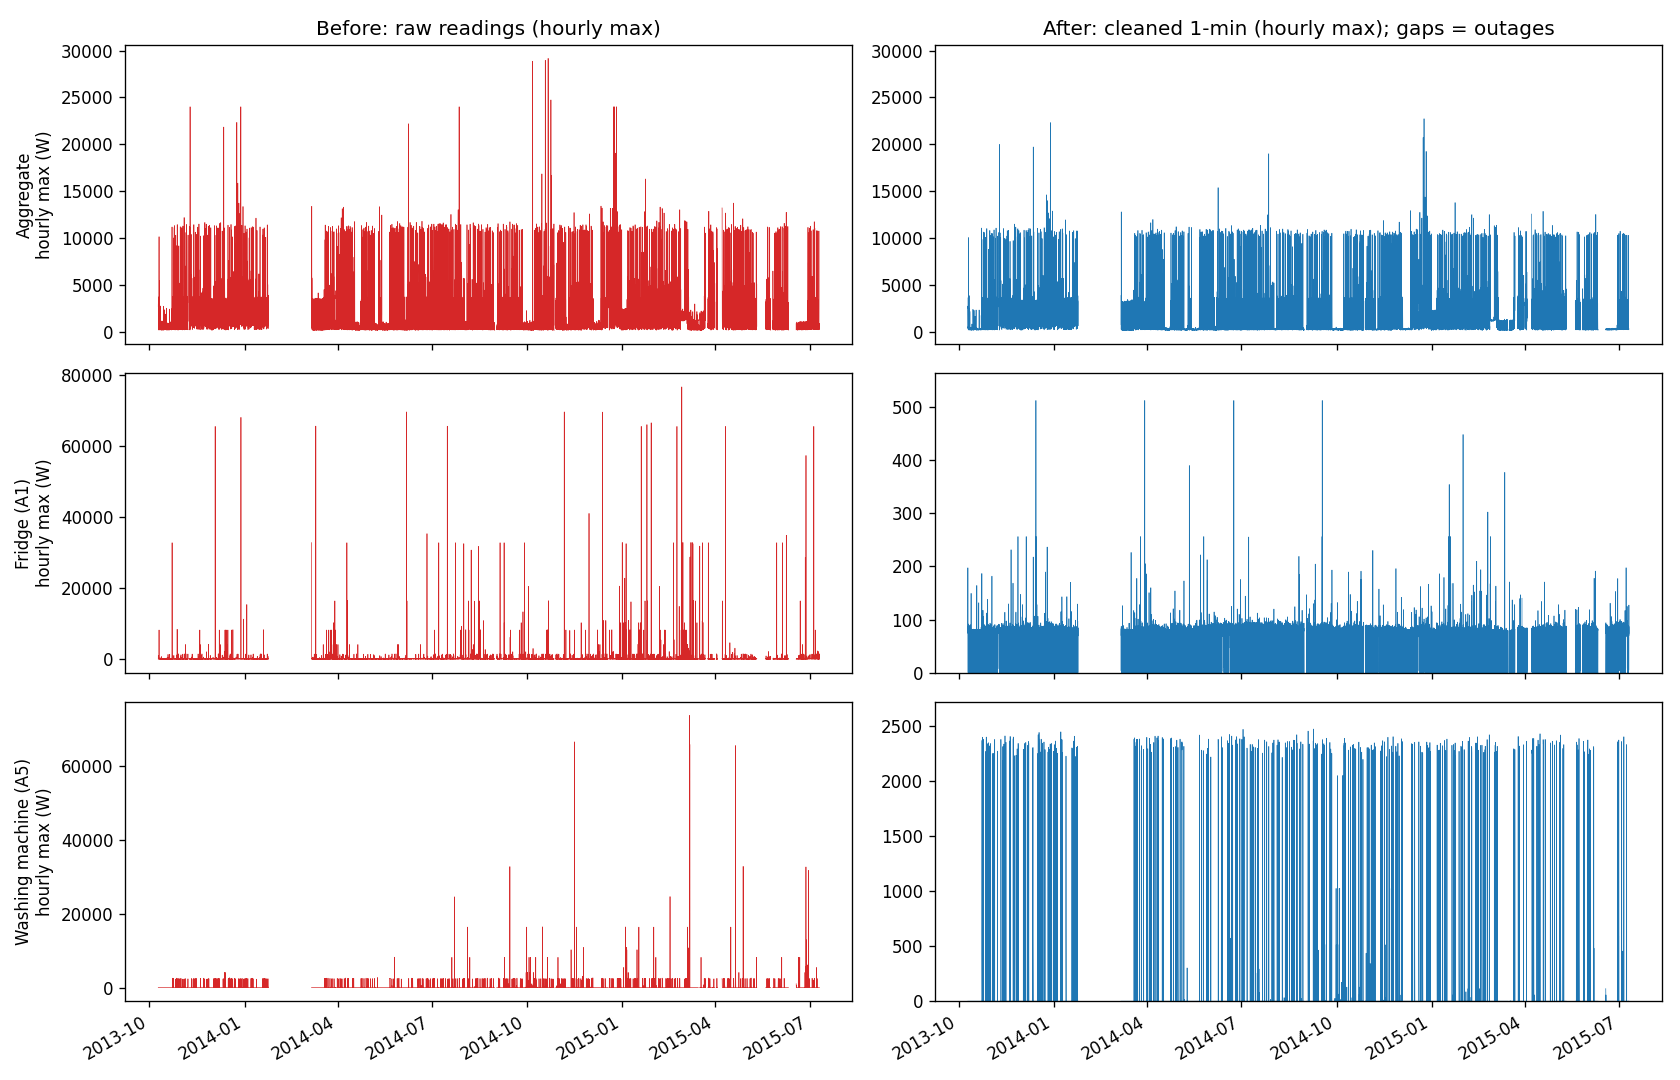

outputs/figures/raw_h1_before_after_day.png


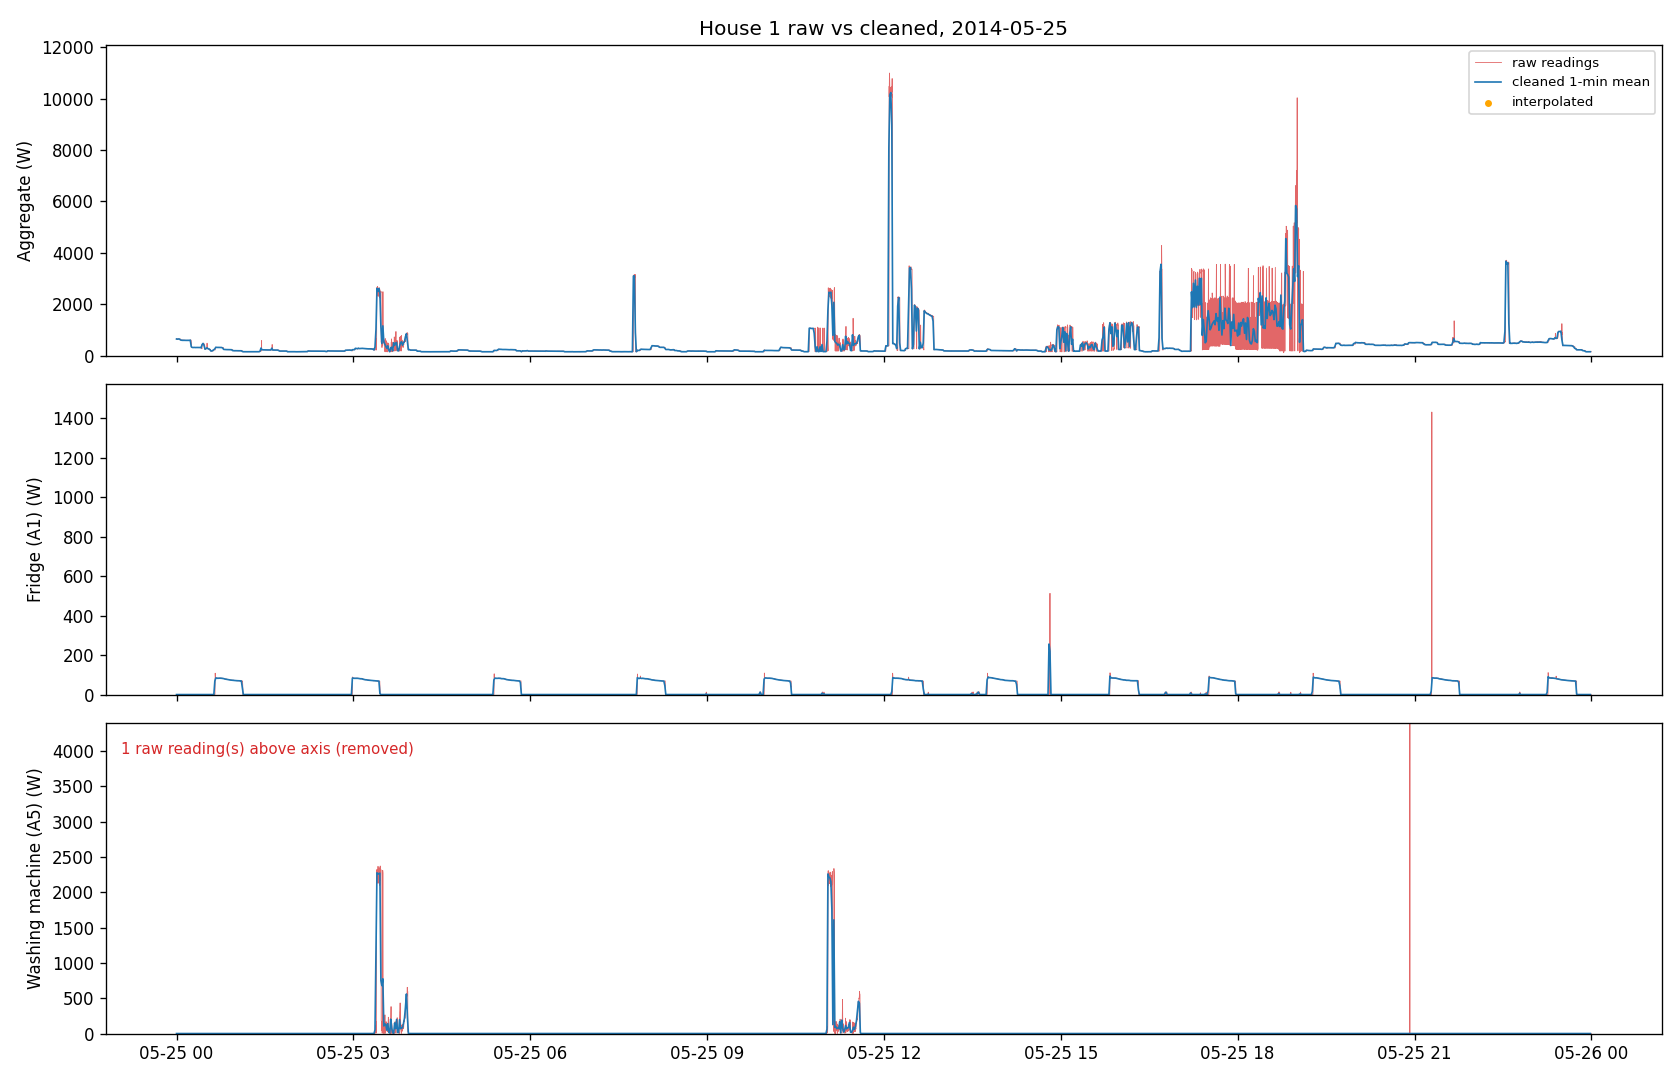

outputs/figures/raw_h1_coverage.png


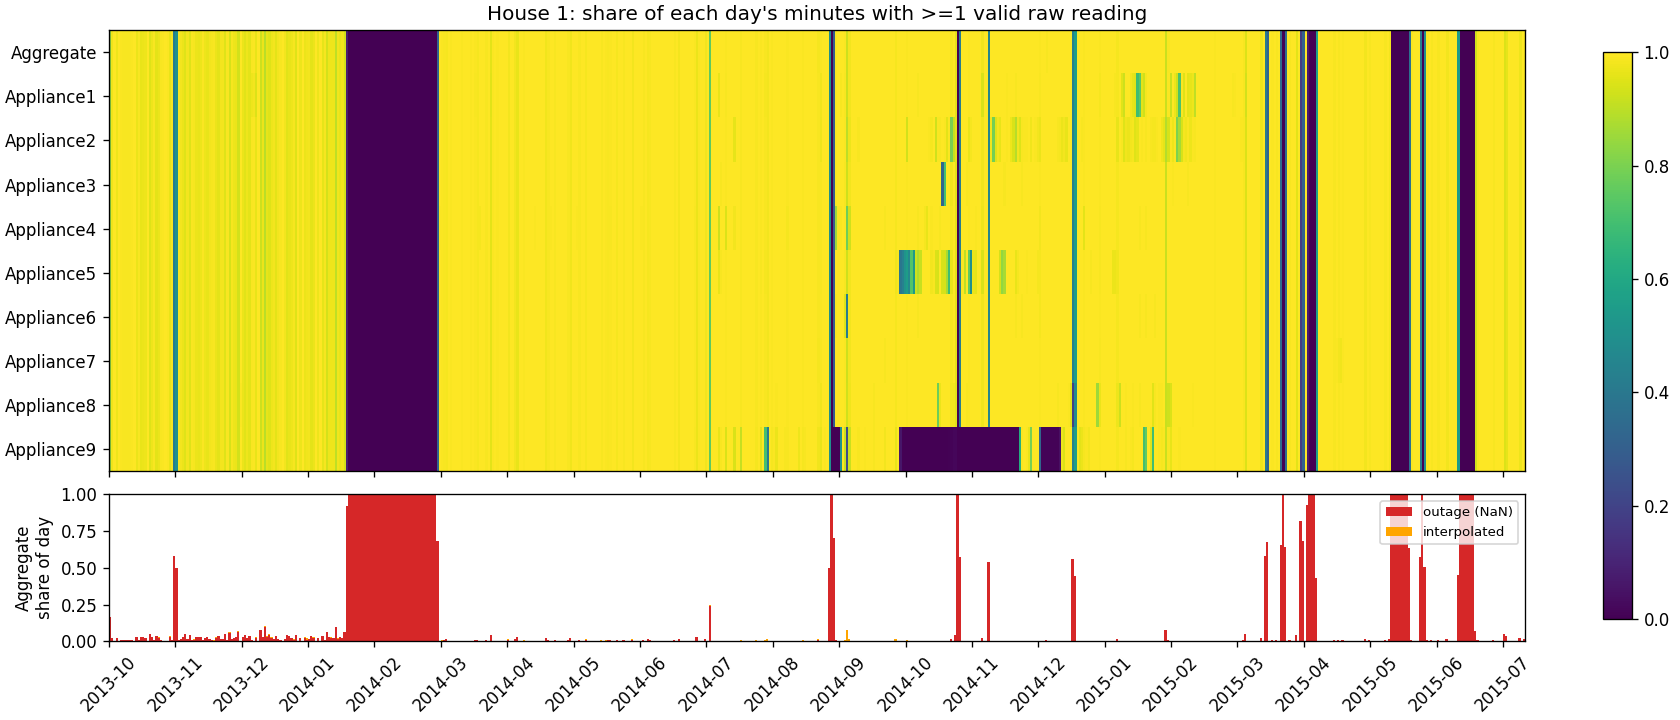

outputs/figures/raw_h1_sampling_intervals.png


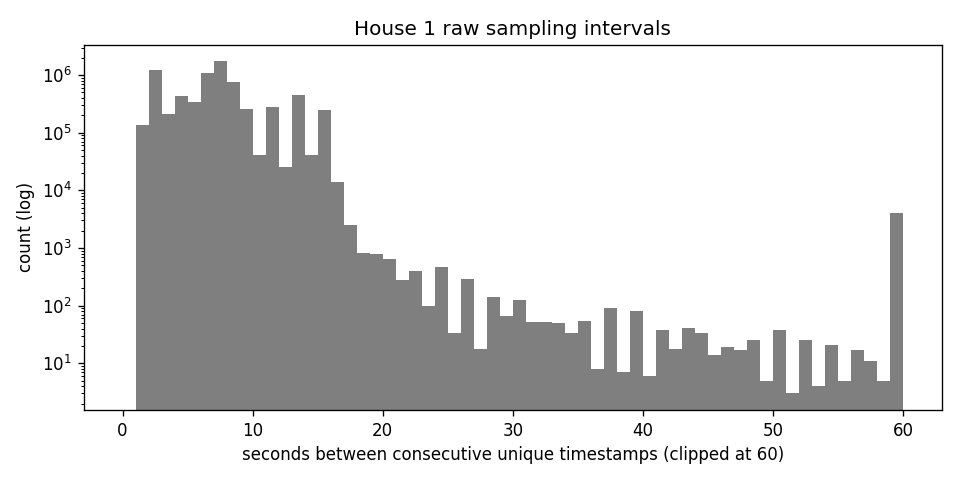

In [23]:
show_fig("raw_h1_before_after_overview")
show_fig("raw_h1_before_after_day")
show_fig("raw_h1_coverage")
show_fig("raw_h1_sampling_intervals")

---
## 2. Official cleaned data for the washing-machine houses

The EDA and model use the **official cleaned REFIT files** (already de-duplicated, DST-corrected,
monitor swaps fixed). They are loaded once per washing-machine house, resampled to 1 minute with the same
≤ 5-minute gap rule, and cached as parquet so later stages load in seconds.

Checks done here, and why:
- **Timezone:** the cleaned `Unix` should be UTC. It is compared with the raw House 1 output from stage 1
  at 0 h and +1 h shifts, separately for winter and summer.
- **Data quality per house:** outage %, `Issues` flag, minutes where WM > aggregate (physically impossible),
  and minutes where the aggregate is **exactly flat for ≥ 60 min** (a stuck, forward-filled sensor).
  These numbers were used to choose the EDA and model houses.

In [24]:
def cache_path(house: int):
    return C.CACHE_DIR / f"clean_house{house}_1min.parquet"

In [25]:
def load_house(house: int, local: bool = True) -> pd.DataFrame:
    """Read a cached house; index converted to UK local time by default."""
    df = pd.read_parquet(cache_path(house))
    return df.tz_convert(C.LOCAL_TZ) if local else df

In [26]:
def flat_minutes(s: pd.Series, min_len=60) -> pd.Series:
    """Minutes inside runs where the 1-min value is exactly unchanged for
    >= min_len minutes. A real household aggregate jitters by a few watts,
    so long flat runs indicate a stuck / forward-filled sensor."""
    same = s.diff().eq(0)
    run_id = (~same).cumsum()
    run_len = s.groupby(run_id).transform("size")
    return s.notna() & (run_len >= min_len)

In [27]:
def prepare_house(house: int):
    wm_col = C.WM_CHANNEL[house]
    src = pd.read_csv(C.clean_file(house), engine="pyarrow",
                      usecols=["Unix", "Aggregate", wm_col, "Issues"])
    checks = {
        "house": house, "wm_channel": wm_col, "rows": len(src),
        "backward_steps": int((src["Unix"].diff() < 0).sum()),
        "duplicate_Unix": int(src["Unix"].duplicated().sum()),
        "missing_cells": int(src.isna().sum().sum()),
        "issues_rows_pct": round(100 * src["Issues"].mean(), 2),
        "wm_gt_4kW_rows": int((src[wm_col] > C.MAX_APPLIANCE_W).sum()),
    }
    src = (src.sort_values("Unix", kind="mergesort")
              .drop_duplicates("Unix", keep="first"))
    src.index = pd.to_datetime(src["Unix"], unit="s", utc=True)
    src = src.rename(columns={"Aggregate": "aggregate", wm_col: "wm"})

    m = src[["aggregate", "wm", "Issues"]].resample(C.RESAMPLE_RULE).mean()
    out = pd.DataFrame(index=m.index)
    out["observed"] = m["aggregate"].notna()
    for c in ("aggregate", "wm"):
        out[c], _ = fill_short_gaps(m[c], C.MAX_INTERP_GAP_MIN)
    out["issues"] = m["Issues"].fillna(0) > 0
    out["wm_gt_agg"] = out["wm"] > out["aggregate"]
    out = out[["aggregate", "wm", "observed", "issues", "wm_gt_agg"]]
    out.to_parquet(cache_path(house))

    valid = out["aggregate"].notna() & out["wm"].notna()
    local = out.index.tz_convert(C.LOCAL_TZ)
    checks.update({
        "start_local": local[0].strftime("%Y-%m-%d"),
        "end_local": local[-1].strftime("%Y-%m-%d"),
        "span_days": round(len(out) / 1440, 1),
        "valid_days": round(valid.sum() / 1440, 1),
        "observed_pct": round(100 * out["observed"].mean(), 2),
        "interpolated_pct": round(100 * (valid & ~out["observed"]).mean(), 2),
        "outage_pct": round(100 * (~valid).mean(), 2),
        "issues_min_pct": round(100 * out["issues"].mean(), 2),
        "wm_gt_agg_min_pct": round(100 * out["wm_gt_agg"].mean(), 3),
        "agg_flat_ge60min_pct": round(100 * flat_minutes(out["aggregate"]).mean(), 2),
        "agg_mean_W": round(out["aggregate"].mean(), 1),
        "wm_mean_W": round(out["wm"].mean(), 1),
        "wm_kWh_per_day": round(out["wm"].mean() * 24 / 1000, 3),
    })
    return checks

In [28]:
def timezone_check():
    """Confirm CLEAN Unix = UTC: compare House 1 clean aggregate with the
    Stage-1 raw-cleaned House 1 (local wall-clock) in a winter and a summer
    window, at 0 and +1 h shifts. Expect best match at 0 h (winter), +1 h (summer)."""
    raw = pd.read_parquet(C.CACHE_DIR / f"house{C.RAW_HOUSE}_raw_cleaned_1min.parquet")["Aggregate"]
    cl = pd.read_parquet(cache_path(C.RAW_HOUSE))["aggregate"]
    cl.index = cl.index.tz_localize(None)
    rows = []
    for season, (a, b) in {"winter": ("2014-01-05", "2014-01-15"),
                           "summer": ("2014-05-05", "2014-05-15")}.items():
        for h in (0, 1):
            x = cl.copy()
            x.index = x.index + pd.Timedelta(hours=h)
            j = pd.concat([x[a:b], raw[a:b]], axis=1).dropna()
            rows.append({"season": season, "window": f"{a}..{b}", "clean_shift_h": h,
                         "corr_with_raw": round(j.corr().iloc[0, 1], 3)})
    return pd.DataFrame(rows)

In [29]:
def run_stage2_prepare_clean():
    C.check_data_available()
    C.ensure_output_dirs()
    rows = []
    for h in sorted(C.WM_CHANNEL):
        rows.append(prepare_house(h))
        print(f"house {h:>2} done", flush=True)
    summary = pd.DataFrame(rows)
    summary.to_csv(C.TAB_DIR / "clean_wm_houses_availability.csv", index=False)
    tz = timezone_check()
    tz.to_csv(C.TAB_DIR / "clean_timezone_check.csv", index=False)
    print(tz.to_string(index=False))
    pd.set_option("display.width", 250, "display.max_columns", 30)
    print(summary.to_string(index=False))

**Run stage 2** (≈ 2 min): build the 1-minute cache for the 18 washing-machine houses.

In [30]:
t = time.time()
run_stage2_prepare_clean()
print(f'stage 2 done in {time.time() - t:.0f} s')

house  1 done


house  2 done


house  3 done


house  5 done


house  6 done


house  7 done


... (9 outputs left out)

house 19 done


house 20 done


house 21 done


season                 window  clean_shift_h  corr_with_raw
winter 2014-01-05..2014-01-15              0          0.999
winter 2014-01-05..2014-01-15              1          0.225
summer 2014-05-05..2014-05-15              0          0.068
summer 2014-05-05..2014-05-15              1          0.999
 house wm_channel    rows  backward_steps  duplicate_Unix  missing_cells  issues_rows_pct  wm_gt_4kW_rows start_local  end_local  span_days  valid_days  observed_pct  interpolated_pct  outage_pct  issues_min_pct  wm_gt_agg_min_pct  agg_flat_ge60min_pct  agg_mean_W  wm_mean_W  wm_kWh_per_day
     1 Appliance5 6960008               0               0              0             0.84               0  2013-10-09 2015-07-10      639.0       558.8         87.36              0.10       12.54            1.81              0.082                  0.31       477.8       10.9           0.261
     2 Appliance2 5733526               0               0              0             0.50               0  2013-09-1

In [31]:
display_table("clean_timezone_check")
display_table("clean_wm_houses_availability")

outputs/tables/clean_timezone_check.csv


,season,window,clean_shift_h,corr_with_raw
0,winter,2014-01-05..2014-01-15,0,0.999
1,winter,2014-01-05..2014-01-15,1,0.225
2,summer,2014-05-05..2014-05-15,0,0.068
3,summer,2014-05-05..2014-05-15,1,0.999


outputs/tables/clean_wm_houses_availability.csv


,house,wm_channel,rows,backward_steps,duplicate_Unix,missing_cells,issues_rows_pct,wm_gt_4kW_rows,start_local,end_local,span_days,valid_days,observed_pct,interpolated_pct,outage_pct,issues_min_pct,wm_gt_agg_min_pct,agg_flat_ge60min_pct,agg_mean_W,wm_mean_W,wm_kWh_per_day
0,1,Appliance5,6960008,0,0,0,0.84,0,2013-10-09,2015-07-10,639.0,558.8,87.36,0.10,12.54,1.81,0.082,0.31,477.8,10.9,0.261
1,2,Appliance2,5733526,0,0,0,0.50,0,2013-09-17,2015-05-28,617.4,465.8,75.38,0.06,24.56,1.51,0.013,0.74,460.8,18.1,0.435
2,3,Appliance6,6994594,0,0,0,5.84,0,2013-09-25,2015-06-02,614.6,545.4,88.62,0.11,11.26,6.85,0.228,12.06,676.9,28.6,0.687
3,5,Appliance3,7430755,0,0,0,5.73,0,2013-09-26,2015-07-06,648.3,589.0,90.66,0.19,9.16,7.59,0.343,0.42,745.1,31.6,0.759
4,6,Appliance2,6241971,0,0,0,0.55,0,2013-11-28,2015-06-28,577.4,490.8,84.75,0.25,15.00,1.75,0.007,0.65,480.8,7.1,0.170
5,7,Appliance5,6756034,0,0,0,2.40,0,2013-11-01,2015-07-08,613.2,536.6,87.42,0.09,12.48,4.06,0.067,0.57,562.0,38.0,0.912
6,8,Appliance4,6118469,0,0,0,0.41,0,2013-11-01,2015-05-11,555.1,498.6,89.73,0.10,10.16,1.54,0.017,1.01,685.1,29.3,0.703
7,9,Appliance3,6169525,0,0,0,0.52,0,2013-12-17,2015-07-08,568.1,481.2,84.62,0.10,15.28,2.02,0.004,4.73,577.0,15.0,0.361
8,10,Appliance5,6739284,0,0,0,0.45,0,2013-11-20,2015-06-30,587.0,523.3,88.80,0.35,10.85,1.65,0.026,7.99,760.9,32.4,0.777
9,11,Appliance3,4431541,0,0,0,0.91,0,2014-06-03,2015-06-30,392.2,349.6,89.05,0.10,10.85,1.73,0.132,1.11,456.3,6.6,0.157


Correlation is ≈ 0.999 at 0 h in winter and +1 h in summer, so the cleaned data is UTC. Houses 3 and 5
(most `Issues` / WM > aggregate), 13 (22.6 % outage) and 11 (shortest record) are not used; houses
8 and 17 are kept back as unseen **test** houses.

---
## 3. Washing-machine EDA (houses 1, 2, 7, 9, 10, 15)

The test houses (8, 17) are deliberately left out, so nothing in the EDA is tuned on them.

**Cycle rule** (on-power threshold + minimum durations, as in Kelly & Knottenbelt 2015):
a minute is *active* when WM power > **20 W**; active stretches separated by pauses **< 10 min** form one
wash (the drum pauses while soaking/draining), never bridging missing data; a wash must last **≥ 10 min**
and use **≥ 50 Wh** (removes door-lock and display blips).

Beyond the required plots, two further questions are answered: **does washing change with the season**
(washes per week and energy per wash by month, normalised by usable days so outages do not look like
months without washing), and **which wash programmes do households use** (washes grouped by length and
heating minutes with k-means; the number of groups is chosen by silhouette score, with every group
holding at least 2 % of washes).

The sensitivity analysis below re-counts washes for on-thresholds of 5–100 W and merge gaps of 0–30 min,
to show the counts do not depend on these choices.

In [32]:
DOW = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

In [33]:
# ------------------------------------------------------------- detection
def detect_cycles(wm: pd.Series, on_w=C.WM_ON_W, merge_gap=C.CYCLE_MERGE_GAP_MIN,
                  min_dur=C.CYCLE_MIN_DURATION_MIN, min_wh=C.CYCLE_MIN_ENERGY_WH,
                  return_runs=False):
    """Return one row per cycle: start, end, duration_min, energy_Wh, peak_W.

    `wm` must be on a regular 1-min grid; NaN = missing.
    """
    x = wm.to_numpy(float)
    xz = np.nan_to_num(x)
    act = xz > on_w
    d = np.diff(np.r_[0, act.astype(np.int8), 0])
    s, e = np.flatnonzero(d == 1), np.flatnonzero(d == -1)   # e exclusive
    n_runs = len(s)
    if n_runs == 0:
        empty = pd.DataFrame(columns=["start", "end", "duration_min", "energy_Wh",
                                      "peak_W", "mean_W"])
        return (empty, 0) if return_runs else empty

    nan_cum = np.r_[0, np.cumsum(np.isnan(x))]
    gap = s[1:] - e[:-1]
    gap_has_nan = (nan_cum[s[1:]] - nan_cum[e[:-1]]) > 0
    merge = (gap < merge_gap) & ~gap_has_nan
    grp = np.r_[0, np.cumsum(~merge)]
    cs = pd.Series(s).groupby(grp).min().to_numpy()
    ce = pd.Series(e).groupby(grp).max().to_numpy()

    csum = np.r_[0, np.cumsum(xz)]
    energy = (csum[ce] - csum[cs]) / 60.0
    xp = np.r_[xz, 0.0]
    peak = np.maximum.reduceat(xp, np.ravel(np.c_[cs, ce]))[::2]
    dur = ce - cs
    idx = wm.index
    cyc = pd.DataFrame({
        "start": idx[cs], "end": idx[ce - 1] + pd.Timedelta(minutes=1),
        "duration_min": dur, "energy_Wh": energy.round(1), "peak_W": peak.round(0),
        "mean_W": (energy * 60 / dur).round(1),
    })
    cyc = cyc[(cyc["duration_min"] >= min_dur) & (cyc["energy_Wh"] >= min_wh)]
    cyc = cyc.reset_index(drop=True)
    return (cyc, n_runs) if return_runs else cyc

In [34]:
def outage_runs(valid: pd.Series, min_len=C.MAX_INTERP_GAP_MIN + 1):
    """Number of contiguous missing stretches of >= min_len minutes."""
    miss = ~valid.to_numpy()
    d = np.diff(np.r_[0, miss.astype(np.int8), 0])
    lens = np.flatnonzero(d == -1) - np.flatnonzero(d == 1)
    return int((lens >= min_len).sum()), (int(lens.max()) if len(lens) else 0)

In [35]:
# ----------------------------------------------------------------- tables
def house_summary(h, df, cyc, n_runs):
    wm = df["wm"]
    valid = wm.notna() & df["aggregate"].notna()
    vdays = valid.sum() / 1440
    n_out, longest = outage_runs(valid)
    starts = cyc["start"]
    wk = starts.dt.dayofweek < 5
    peak = wk & starts.dt.hour.isin(C.UK_PEAK_HOURS)
    return {
        "house": h, "wm_channel": C.WM_CHANNEL.get(h, "-"),
        "start": df.index[0].strftime("%Y-%m-%d"), "end": df.index[-1].strftime("%Y-%m-%d"),
        "span_days": round(len(df) / 1440, 1), "valid_days": round(vdays, 1),
        "missing_pct": round(100 * (1 - valid.mean()), 2),
        "outages_gt5min": n_out, "longest_outage_days": round(longest / 1440, 1),
        "wm_exact_zero_pct": round(100 * (wm[valid] == 0).mean(), 1),
        "wm_off_pct": round(100 * (wm[valid] <= C.WM_ON_W).mean(), 2),
        "issues_pct": round(100 * df.loc[valid, "issues"].mean(), 2),
        "active_runs": n_runs, "cycles": len(cyc),
        "cycles_per_week": round(len(cyc) / vdays * 7, 2),
        "median_duration_min": cyc["duration_min"].median(),
        "median_energy_Wh": cyc["energy_Wh"].median(),
        "median_peak_W": cyc["peak_W"].median(),
        "wm_share_of_house_energy_pct": round(
            100 * wm[valid].sum() / df.loc[valid, "aggregate"].sum(), 2),
        "pct_cycles_in_cycle_energy": round(
            100 * cyc["energy_Wh"].sum() / (wm[valid].sum() / 60), 1),
        "pct_cycles_weekend": round(100 * (~wk).mean(), 1),
        "pct_cycles_weekday_16_20": round(100 * peak.mean(), 1),
    }

In [36]:
def sensitivity(data):
    rows = []
    for h, df in data.items():
        vdays = (df["wm"].notna() & df["aggregate"].notna()).sum() / 1440
        for on_w in C.SENSITIVITY_ON_W:
            cyc = detect_cycles(df["wm"], on_w=on_w)
            rows.append({"house": h, "vary": "on_W", "value": on_w,
                         "cycles_per_week": round(len(cyc) / vdays * 7, 2),
                         "median_duration_min": cyc["duration_min"].median(),
                         "median_energy_Wh": cyc["energy_Wh"].median()})
        for mg in C.SENSITIVITY_MERGE_MIN:
            cyc = detect_cycles(df["wm"], merge_gap=mg)
            rows.append({"house": h, "vary": "merge_gap_min", "value": mg,
                         "cycles_per_week": round(len(cyc) / vdays * 7, 2),
                         "median_duration_min": cyc["duration_min"].median(),
                         "median_energy_Wh": cyc["energy_Wh"].median()})
    return pd.DataFrame(rows)

In [37]:
# ------------------------------------------------------------------ plots
def plot_example_day(df, cyc, h, path):
    """Day whose single cycle has energy closest to the house median."""
    day_ok = df["aggregate"].notna().groupby(df.index.date).all()
    per_day = cyc.groupby(cyc["start"].dt.date).size()
    cand = cyc[cyc["start"].dt.date.map(lambda d: per_day.get(d, 0) == 1
                                         and day_ok.get(d, False))]
    pick = cand.iloc[(cand["energy_Wh"] - cyc["energy_Wh"].median()).abs().argmin()]
    day = pick["start"].normalize()
    w = df.loc[day: day + pd.Timedelta(days=1) - pd.Timedelta(minutes=1)]
    fig, ax = plt.subplots(figsize=(13, 4.5))
    ax.plot(w.index, w["aggregate"], lw=0.8, color="0.45", label="household aggregate")
    ax.fill_between(w.index, 0, w["wm"], color="tab:blue", alpha=0.6, label="washing machine")
    ax.axvspan(pick["start"], pick["end"], color="tab:orange", alpha=0.15,
               label=f"detected cycle ({pick['duration_min']} min, {pick['energy_Wh']:.0f} Wh)")
    ax.set_ylabel("power (W)")
    ax.set_title(f"House {h}, {day.strftime('%a %d %b %Y')} (local time): aggregate vs washing machine")
    ax.legend(loc="upper left", fontsize=8)
    ax.xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%H:%M", tz=C.LOCAL_TZ))
    fig.tight_layout()
    fig.savefig(path, dpi=120)
    plt.close(fig)
    return day, pick

In [38]:
def plot_cycle_detail(df, pick, h, path):
    a = pick["start"] - pd.Timedelta(minutes=30)
    b = pick["end"] + pd.Timedelta(minutes=30)
    w = df.loc[a:b]
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(w.index, w["wm"], color="tab:blue", lw=1.2, label="WM 1-min mean")
    act = w["wm"] > C.WM_ON_W
    ax.scatter(w.index[act], w["wm"][act], s=6, color="tab:blue")
    ax.axhline(C.WM_ON_W, color="tab:red", ls="--", lw=1, label=f"on threshold {C.WM_ON_W} W")
    ax.axvspan(pick["start"], pick["end"], color="tab:orange", alpha=0.15, label="detected cycle")
    ax.set_yscale("symlog", linthresh=50)
    ax.set_ylim(0, w["wm"].max() * 1.5)
    ax.set_ylabel("power (W, log above 50 W)")
    ax.set_title(f"House {h}: one detected cycle - heating burst(s), tumbling, spin; "
                 f"pauses < {C.CYCLE_MERGE_GAP_MIN} min are bridged")
    ax.legend(fontsize=8, loc="upper right")
    ax.xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%H:%M", tz=C.LOCAL_TZ))
    fig.tight_layout()
    fig.savefig(path, dpi=120)
    plt.close(fig)

In [39]:
def plot_cycle_gallery(data, cycles, path, n=15):
    rng = np.random.default_rng(C.RANDOM_SEED)
    fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
    for ax, h in zip(axes.ravel(), data):
        cyc = cycles[cycles["house"] == h]
        pick = cyc.iloc[rng.choice(len(cyc), size=min(n, len(cyc)), replace=False)]
        for _, r in pick.iterrows():
            w = data[h]["wm"].loc[r["start"]: r["end"]]
            ax.plot(np.arange(len(w)), w.values, lw=0.7, alpha=0.6)
        ax.set_title(f"House {h} ({len(cyc)} cycles; {n} random shown)")
        ax.set_xlabel("minutes since cycle start")
    axes[0, 0].set_ylabel("WM power (W)")
    axes[1, 0].set_ylabel("WM power (W)")
    fig.tight_layout()
    fig.savefig(path, dpi=120)
    plt.close(fig)

In [40]:
def plot_time_patterns(cycles, path):
    houses = sorted(cycles["house"].unique())
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5), width_ratios=[2, 1])
    hrs = np.arange(24)
    for h in houses:
        s = cycles.loc[cycles["house"] == h, "start"]
        share = s.dt.hour.value_counts(normalize=True).reindex(hrs, fill_value=0) * 100
        ax1.plot(hrs, share.values, marker="o", ms=3, lw=1, label=f"House {h}")
    allh = cycles["start"].dt.hour.value_counts(normalize=True).reindex(hrs, fill_value=0) * 100
    ax1.plot(hrs, allh.values, color="k", lw=2.5, label="all 6 houses")
    ax1.axvspan(C.UK_PEAK_HOURS.start - 0.5, C.UK_PEAK_HOURS.stop - 0.5, color="tab:red",
                alpha=0.08, label="16-20h network peak")
    ax1.set_xticks(hrs)
    ax1.set_xlabel("hour of cycle start (local)")
    ax1.set_ylabel("% of house's cycles")
    ax1.legend(fontsize=7, ncol=2)
    ax1.set_title("When do washes start? (hour of day)")
    width = 0.8 / len(houses)
    for i, h in enumerate(houses):
        s = cycles.loc[cycles["house"] == h, "start"]
        share = s.dt.dayofweek.value_counts(normalize=True).reindex(range(7), fill_value=0) * 100
        ax2.bar(np.arange(7) + i * width - 0.4 + width / 2, share.values, width, label=f"H{h}")
    ax2.axhline(100 / 7, color="k", ls="--", lw=1, label="uniform")
    ax2.set_xticks(range(7), DOW)
    ax2.set_ylabel("% of house's cycles")
    ax2.set_title("Day of week")
    ax2.legend(fontsize=7, ncol=2)
    fig.tight_layout()
    fig.savefig(path, dpi=120)
    plt.close(fig)

In [41]:
def plot_heatmap(cycles, path):
    s = cycles["start"]
    tab = pd.crosstab(s.dt.dayofweek, s.dt.hour).reindex(index=range(7), columns=range(24),
                                                        fill_value=0)
    fig, ax = plt.subplots(figsize=(12, 3.5))
    im = ax.imshow(tab.values, aspect="auto", cmap="Blues")
    ax.set_yticks(range(7), DOW)
    ax.set_xticks(range(24))
    ax.set_xlabel("hour of cycle start (local)")
    ax.set_title(f"Cycle starts, all EDA houses pooled (n={len(cycles)})")
    fig.colorbar(im, ax=ax, label="cycles")
    fig.tight_layout()
    fig.savefig(path, dpi=120)
    plt.close(fig)

In [42]:
def plot_cross_house(cycles, path):
    houses = sorted(cycles["house"].unique())
    metrics = [("duration_min", "duration (min)"), ("energy_Wh", "energy per cycle (Wh)"),
               ("peak_W", "peak power (W)")]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    for ax, (col, lab) in zip(axes, metrics):
        vals = [cycles.loc[cycles["house"] == h, col].values for h in houses]
        ax.boxplot(vals, showfliers=False)
        ax.set_xticks(range(1, len(houses) + 1), [f"H{h}" for h in houses])
        ax.set_title(lab)
    fig.suptitle("Washing-machine cycle characteristics by house (box = IQR, whiskers 1.5 IQR, "
                 "outliers hidden)")
    fig.tight_layout()
    fig.savefig(path, dpi=120)
    plt.close(fig)

In [43]:
def plot_sensitivity(sens, path):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, (vary, lab) in zip(axes, [("on_W", "on threshold (W)"),
                                      ("merge_gap_min", "merge gap (min)")]):
        s = sens[sens["vary"] == vary]
        for h, g in s.groupby("house"):
            ax.plot(g["value"], g["cycles_per_week"], marker="o", label=f"House {h}")
        ref = C.WM_ON_W if vary == "on_W" else C.CYCLE_MERGE_GAP_MIN
        ax.axvline(ref, color="k", ls="--", lw=1)
        ax.set_xlabel(lab)
        ax.set_ylabel("detected cycles per week")
    axes[0].set_xscale("log")
    axes[0].legend(fontsize=7)
    fig.suptitle("Cycle-rule sensitivity (dashed = chosen value)")
    fig.tight_layout()
    fig.savefig(path, dpi=120)
    plt.close(fig)

In [44]:
# ------------------------------------------------------------ seasonality
MIN_MONTH_DAYS = 7   # house-months with less usable data are left out


def seasonality(data, cycles):
    """Washes per week and energy per wash by calendar month.

    Counts are divided by the usable (non-missing) days of that house-month,
    so outages do not look like months without washing."""
    rows = []
    for h, df in data.items():
        usable = df["wm"].notna().groupby(df.index.month).sum() / 1440
        cyc = cycles[cycles["house"] == h]
        n = cyc["start"].dt.month.value_counts()
        for mth, days in usable.items():
            if days < MIN_MONTH_DAYS:
                continue
            k = int(n.get(mth, 0))
            rows.append({"house": h, "month": mth, "usable_days": round(days, 1), "cycles": k,
                         "cycles_per_week": round(7 * k / days, 2)})
    per_house = pd.DataFrame(rows)
    pooled = per_house.groupby("month")[["usable_days", "cycles"]].sum()
    pooled["cycles_per_week"] = (7 * pooled["cycles"] / pooled["usable_days"]).round(2)
    pooled["median_energy_Wh"] = cycles.groupby(cycles["start"].dt.month)["energy_Wh"].median()
    pooled["median_heater_min"] = cycles.groupby(cycles["start"].dt.month)["heater_min"].median()
    pooled = pooled.reset_index().assign(house="pooled")
    return pd.concat([per_house, pooled], ignore_index=True)

In [45]:
def plot_seasonality(seas, path):
    mon = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
    ph = seas[seas["house"] != "pooled"]
    for h, g in ph.groupby("house"):
        ax1.plot(g["month"], g["cycles_per_week"], marker="o", lw=1, alpha=0.6, label=f"House {h}")
    p = seas[seas["house"] == "pooled"]
    ax1.plot(p["month"], p["cycles_per_week"], color="k", lw=2.5, marker="o", label="pooled")
    ax1.set_ylabel("washes per week (per usable day)")
    ax1.set_title("Washes per week by month")
    ax1.legend(fontsize=7, ncol=2)
    ax2.bar(p["month"], p["median_energy_Wh"], color="tab:orange")
    ax2.set_ylabel("median energy per wash (Wh)")
    ax2.set_title("Energy per wash by month (pooled)")
    for ax in (ax1, ax2):
        ax.set_xticks(range(1, 13), mon)
    fig.tight_layout()
    fig.savefig(path, dpi=120)
    plt.close(fig)

In [46]:
# ---------------------------------------------------- wash programmes
HEATER_W = 1_000          # a minute above this is a heating minute
PROGRAMME_K = range(2, 7)  # candidate numbers of programme groups
MIN_GROUP_SHARE = 0.02     # a programme must hold >= 2 % of washes (no outlier groups)


def heater_minutes(wm, cyc):
    """Number of minutes above HEATER_W inside each cycle."""
    hot = np.r_[0, np.cumsum(np.nan_to_num(wm.to_numpy(float)) > HEATER_W)]
    pos = wm.index.get_indexer(cyc["start"])
    return hot[pos + cyc["duration_min"].to_numpy()] - hot[pos]

In [47]:
def programmes(cycles):
    """Group washes into programme types by length and heating time.

    k-means on standardised [log duration, heating minutes]; the number of
    groups is the one with the best silhouette score among PROGRAMME_K whose
    groups all hold at least MIN_GROUP_SHARE of the washes."""
    from sklearn.cluster import KMeans
    from sklearn.metrics import silhouette_score
    X = np.c_[np.log(cycles["duration_min"]), cycles["heater_min"]]
    X = (X - X.mean(0)) / X.std(0)
    best = None
    sil = {}
    for k in PROGRAMME_K:
        lab = KMeans(k, n_init=10, random_state=C.RANDOM_SEED).fit_predict(X)
        sil[k] = silhouette_score(X, lab, sample_size=min(len(X), 3000),
                                  random_state=C.RANDOM_SEED)
        big_enough = np.bincount(lab).min() >= MIN_GROUP_SHARE * len(lab)
        if big_enough and (best is None or sil[k] > sil[best[0]]):
            best = (k, lab)
    k, lab = best
    # name groups by median duration (P1 = shortest)
    order = pd.Series(cycles["duration_min"].values).groupby(lab).median().sort_values().index
    names = {old: f"P{i + 1}" for i, old in enumerate(order)}
    prog = pd.Series(lab).map(names).to_numpy()
    return prog, pd.Series(sil).round(3)

In [48]:
def programme_table(cycles):
    loc = cycles["start"]
    peak = (loc.dt.dayofweek < 5) & loc.dt.hour.isin(C.UK_PEAK_HOURS)
    g = cycles.assign(peak=peak).groupby("programme")
    tab = pd.DataFrame({
        "washes": g.size(),
        "share_pct": (100 * g.size() / len(cycles)).round(1),
        "median_duration_min": g["duration_min"].median(),
        "median_heater_min": g["heater_min"].median(),
        "median_energy_Wh": g["energy_Wh"].median().round(0),
        "share_starting_weekday_peak_pct": (100 * g["peak"].mean()).round(1),
    })
    by_house = (pd.crosstab(cycles["house"], cycles["programme"], normalize="index") * 100).round(1)
    return tab, by_house

In [49]:
def plot_programmes(cycles, by_house, path):
    progs = sorted(cycles["programme"].unique())
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
    for p in progs:
        g = cycles[cycles["programme"] == p]
        ax1.scatter(g["duration_min"], g["heater_min"], s=6, alpha=0.4, label=p)
    ax1.set_xscale("log")
    ax1.set_xlabel("wash duration (min, log scale)")
    ax1.set_ylabel(f"heating minutes (WM > {HEATER_W} W)")
    ax1.set_title("Washes grouped into programme types")
    ax1.legend(markerscale=3)
    bottom = np.zeros(len(by_house))
    for p in progs:
        v = by_house[p].to_numpy() if p in by_house else np.zeros(len(by_house))
        ax2.bar([f"H{h}" for h in by_house.index], v, bottom=bottom, label=p)
        bottom += v
    ax2.set_ylabel("% of the house's washes")
    ax2.set_title("Programme mix by house")
    ax2.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(path, dpi=120)
    plt.close(fig)

In [50]:
# ------------------------------------------------------------------- main
def run_stage3_eda():
    C.ensure_output_dirs()
    data = {h: load_house(h) for h in C.EDA_HOUSES}
    rows, all_cyc = [], []
    for h, df in data.items():
        cyc, n_runs = detect_cycles(df["wm"], return_runs=True)
        rows.append(house_summary(h, df, cyc, n_runs))
        all_cyc.append(cyc.assign(house=h, heater_min=heater_minutes(df["wm"], cyc)))
    cycles = pd.concat(all_cyc, ignore_index=True)
    cycles["programme"], sil = programmes(cycles)
    rows.append(house_summary("pooled", pd.concat(data.values()), cycles, sum(
        r["active_runs"] for r in rows)) | {"wm_channel": "-", "start": "-", "end": "-"})
    summary = pd.DataFrame(rows)
    summary.to_csv(C.TAB_DIR / "eda_wm_summary.csv", index=False)
    cycles.to_csv(C.TAB_DIR / "eda_wm_cycles.csv", index=False)

    hourly = pd.crosstab(cycles["house"], cycles["start"].dt.hour, normalize="index") * 100
    hourly.loc["pooled"] = cycles["start"].dt.hour.value_counts(normalize=True) \
        .reindex(hourly.columns, fill_value=0) * 100
    hourly.round(1).to_csv(C.TAB_DIR / "eda_wm_hourly_share_pct.csv")

    sens = sensitivity(data)
    sens.to_csv(C.TAB_DIR / "eda_wm_sensitivity.csv", index=False)

    h = C.EDA_EXAMPLE_HOUSE
    day, pick = plot_example_day(data[h], cycles[cycles["house"] == h], h,
                                 C.FIG_DIR / "eda_wm_example_day.png")
    plot_cycle_detail(data[h], pick, h, C.FIG_DIR / "eda_wm_cycle_detail.png")
    plot_cycle_gallery(data, cycles, C.FIG_DIR / "eda_wm_cycle_gallery.png")
    plot_time_patterns(cycles, C.FIG_DIR / "eda_wm_time_patterns.png")
    plot_heatmap(cycles, C.FIG_DIR / "eda_wm_dow_hour_heatmap.png")
    plot_cross_house(cycles, C.FIG_DIR / "eda_wm_cross_house.png")
    plot_sensitivity(sens, C.FIG_DIR / "eda_wm_sensitivity.png")

    seas = seasonality(data, cycles)
    seas.to_csv(C.TAB_DIR / "eda_wm_seasonality.csv", index=False)
    plot_seasonality(seas, C.FIG_DIR / "eda_wm_seasonality.png")
    prog, prog_house = programme_table(cycles)
    prog.to_csv(C.TAB_DIR / "eda_wm_programmes.csv")
    prog_house.to_csv(C.TAB_DIR / "eda_wm_programmes_by_house.csv")
    sil.rename_axis("k").rename("silhouette").to_csv(C.TAB_DIR / "eda_wm_programme_k.csv")
    plot_programmes(cycles, prog_house, C.FIG_DIR / "eda_wm_programmes.png")

    pd.set_option("display.width", 250, "display.max_columns", 40)
    print(summary.T.to_string())
    print(sens.pivot_table(index=["vary", "value"], columns="house",
                           values="cycles_per_week").to_string())
    print("example day:", day.date(), "cycle:", pick.to_dict())
    print(seas[seas["house"] == "pooled"].to_string(index=False))
    print("silhouette by k:", sil.to_dict())
    print(prog.to_string())
    print(prog_house.to_string())

**Run stage 3** (≈ 10 s): detect cycles, summarise, run the sensitivity analysis and draw the plots.

In [51]:
t = time.time()
run_stage3_eda()
print(f'stage 3 done in {time.time() - t:.0f} s')

                                       0           1           2           3           4           5       6
house                                  1           2           7           9          10          15  pooled
wm_channel                    Appliance5  Appliance2  Appliance5  Appliance3  Appliance5  Appliance3       -
start                         2013-10-09  2013-09-17  2013-11-01  2013-12-17  2013-11-20  2013-12-17       -
end                           2015-07-10  2015-05-28  2015-07-08  2015-07-08  2015-06-30  2015-07-08       -
span_days                          639.0       617.4       613.2       568.1       587.0       567.4  3592.0
valid_days                         558.8       465.8       536.6       481.2       523.3       490.8  3056.6
missing_pct                        12.54       24.56       12.48       15.28       10.85        13.5   14.91
outages_gt5min                       406         463         118          79         788         691    2545
longest_outage_days

### Availability, cycles per house and sensitivity

In [52]:
display_table("eda_wm_summary")
display_table("eda_wm_sensitivity")

outputs/tables/eda_wm_summary.csv


,house,wm_channel,start,end,span_days,valid_days,missing_pct,outages_gt5min,longest_outage_days,wm_exact_zero_pct,wm_off_pct,issues_pct,active_runs,cycles,cycles_per_week,median_duration_min,median_energy_Wh,median_peak_W,wm_share_of_house_energy_pct,pct_cycles_in_cycle_energy,pct_cycles_weekend,pct_cycles_weekday_16_20
0,1,Appliance5,2013-10-09,2015-07-10,639.0,558.8,12.54,406,41.6,97.6,98.12,2.07,1769,400,5.01,33.0,317.00,2326.0,2.28,98.9,22.8,2.2
1,2,Appliance2,2013-09-17,2015-05-28,617.4,465.8,24.56,463,62.0,94.4,95.32,2.01,1909,337,5.06,97.0,610.00,2090.0,3.93,99.5,25.2,14.2
2,7,Appliance5,2013-11-01,2015-07-08,613.2,536.6,12.48,118,41.6,74.9,91.62,4.64,1148,857,11.18,60.0,541.40,2083.0,6.76,99.7,28.7,15.2
3,9,Appliance3,2013-12-17,2015-07-08,568.1,481.2,15.28,79,41.6,90.6,97.32,2.39,342,248,3.61,73.0,642.15,2210.0,2.61,99.4,51.2,17.7
4,10,Appliance5,2013-11-20,2015-06-30,587.0,523.3,10.85,788,8.6,90.2,91.28,1.85,2406,604,8.08,120.0,711.40,2055.5,4.26,98.9,26.8,29.0
5,15,Appliance3,2013-12-17,2015-07-08,567.4,490.8,13.50,691,8.6,96.1,97.08,1.62,1290,258,3.68,90.5,687.75,2179.5,6.74,98.3,28.3,12.4
6,pooled,-,-,-,3592.0,3056.6,14.91,2545,62.0,90.5,95.09,2.45,8864,2704,6.19,77.0,586.50,2102.0,4.26,99.2,29.0,16.2


outputs/tables/eda_wm_sensitivity.csv


,house,vary,value,cycles_per_week,median_duration_min,median_energy_Wh
0,1,on_W,5,4.96,34.0,318.80
1,1,on_W,10,4.97,34.0,318.00
2,1,on_W,20,5.01,33.0,317.00
3,1,on_W,50,4.99,33.0,316.80
4,1,on_W,100,4.99,32.0,314.30
5,1,merge_gap_min,0,5.80,15.0,250.50
6,1,merge_gap_min,5,5.35,33.0,303.40
7,1,merge_gap_min,10,5.01,33.0,317.00
8,1,merge_gap_min,20,4.73,33.0,321.50
9,1,merge_gap_min,30,4.61,33.0,322.60


In [53]:
display_table("eda_wm_cycles", n=10)

outputs/tables/eda_wm_cycles.csv


,start,end,duration_min,energy_Wh,peak_W,mean_W,house,heater_min,programme
0,2013-10-23 06:59:00+01:00,2013-10-23 08:16:00+01:00,77,534.5,2369.0,416.5,1,11,P2
1,2013-10-23 14:05:00+01:00,2013-10-23 14:37:00+01:00,32,277.7,2370.0,520.8,1,6,P1
2,2013-10-23 15:06:00+01:00,2013-10-23 15:40:00+01:00,34,277.5,2401.0,489.7,1,6,P1
3,2013-10-24 11:11:00+01:00,2013-10-24 11:43:00+01:00,32,265.0,2379.0,496.9,1,6,P1
4,2013-10-26 12:34:00+01:00,2013-10-26 13:09:00+01:00,35,283.0,2267.0,485.2,1,6,P1
5,2013-10-27 10:06:00+00:00,2013-10-27 11:20:00+00:00,74,530.2,2399.0,429.9,1,12,P2
6,2013-10-28 13:30:00+00:00,2013-10-28 14:02:00+00:00,32,272.1,2347.0,510.2,1,6,P1
7,2013-10-29 10:55:00+00:00,2013-10-29 11:36:00+00:00,41,383.0,2340.0,560.4,1,10,P1
8,2013-10-29 12:08:00+00:00,2013-10-29 12:42:00+00:00,34,291.5,2344.0,514.3,1,6,P1
9,2013-10-30 14:54:00+00:00,2013-10-30 15:27:00+00:00,33,334.3,2314.0,607.8,1,8,P1


### Plot (i): a representative 24 hours
Chosen automatically (complete day, one wash, wash energy closest to the house median). The WM is visible in
the aggregate mainly during its ~2 kW heating phase, and other 2–3 kW loads look similar, which is why
disaggregation is hard.

outputs/figures/eda_wm_example_day.png


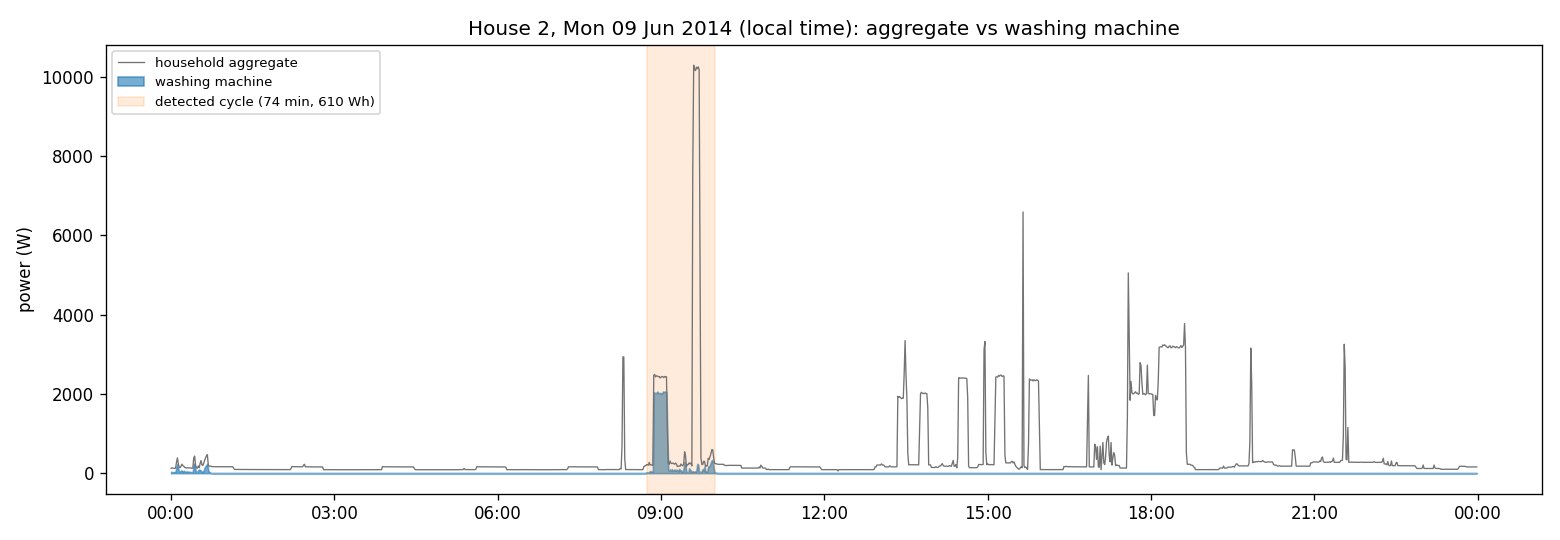

In [54]:
show_fig("eda_wm_example_day")

### Plot (ii): detected cycles: one wash in detail, and 15 random washes per house

outputs/figures/eda_wm_cycle_detail.png


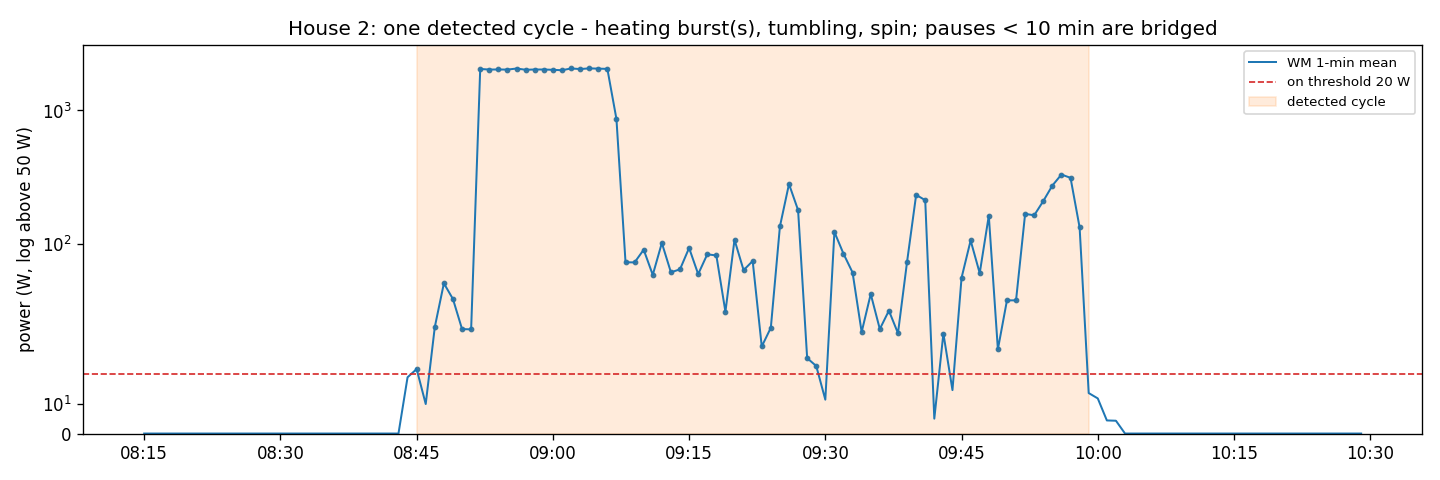

outputs/figures/eda_wm_cycle_gallery.png


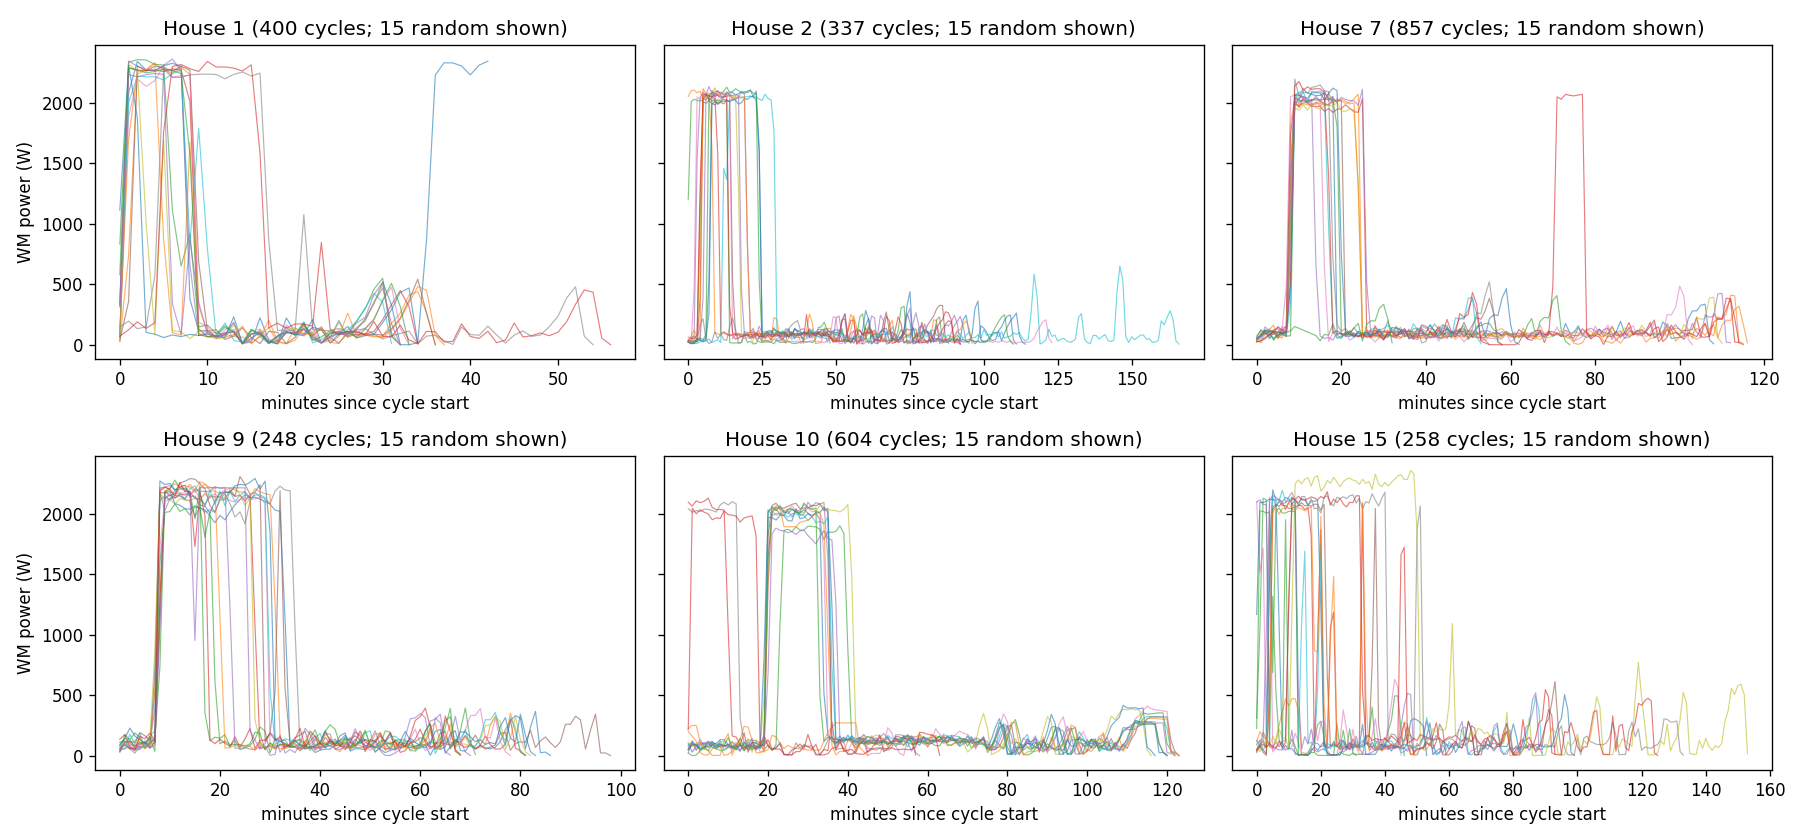

In [55]:
show_fig("eda_wm_cycle_detail")
show_fig("eda_wm_cycle_gallery")

### Usage patterns: hour of day and day of week

outputs/figures/eda_wm_time_patterns.png


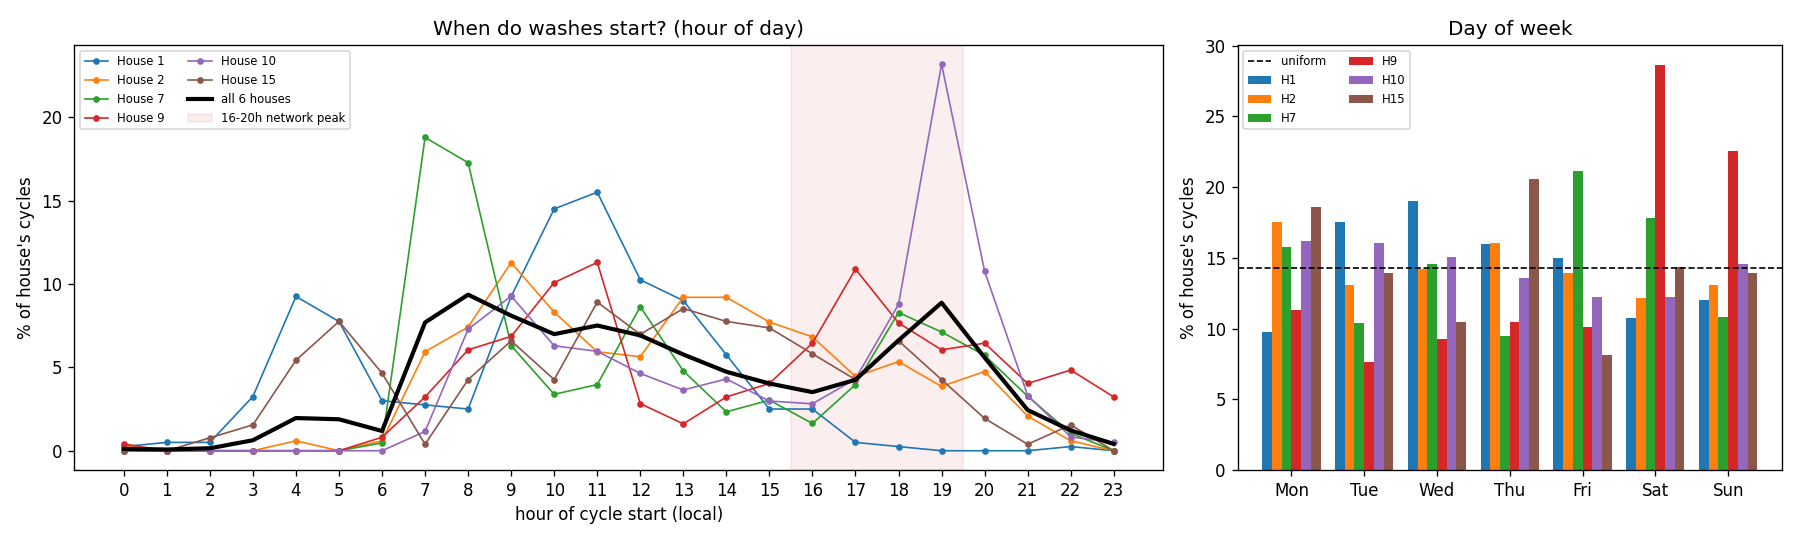

outputs/figures/eda_wm_dow_hour_heatmap.png


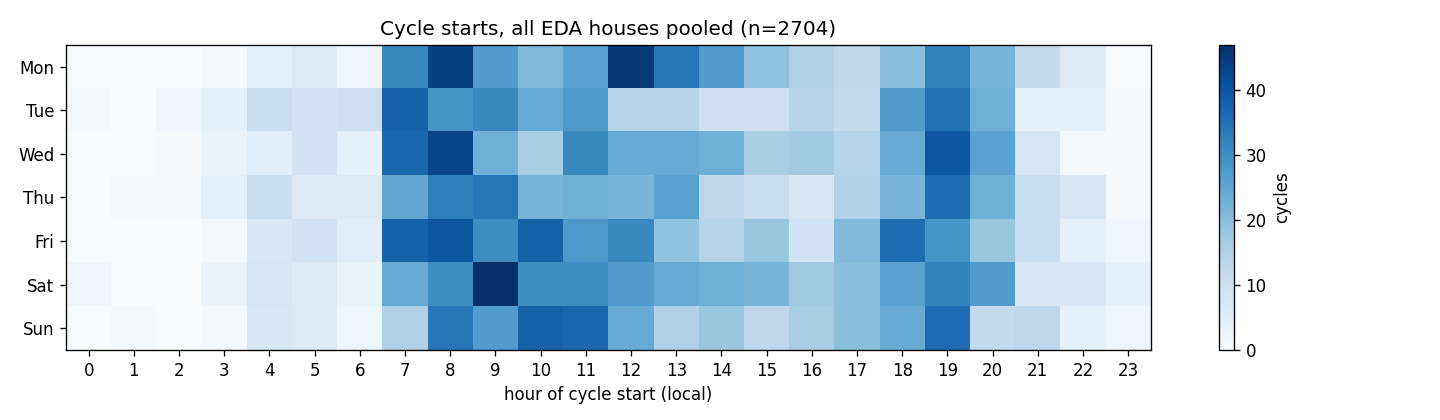

In [56]:
show_fig("eda_wm_time_patterns")
show_fig("eda_wm_dow_hour_heatmap")

In [57]:
display_table("eda_wm_hourly_share_pct")

outputs/tables/eda_wm_hourly_share_pct.csv


,house,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
0,1,0.2,0.5,0.5,3.2,9.2,7.8,3.0,2.8,2.5,9.2,14.5,15.5,10.2,9.0,5.8,2.5,2.5,0.5,0.2,0.0,0.0,0.0,0.2,0.0
1,2,0.3,0.0,0.0,0.0,0.6,0.0,0.6,5.9,7.4,11.3,8.3,5.9,5.6,9.2,9.2,7.7,6.8,4.5,5.3,3.9,4.7,2.1,0.6,0.0
2,7,0.0,0.0,0.0,0.0,0.0,0.0,0.5,18.8,17.3,6.3,3.4,4.0,8.6,4.8,2.3,3.0,1.6,4.0,8.3,7.1,5.7,3.3,1.1,0.0
3,9,0.4,0.0,0.0,0.0,0.0,0.0,0.8,3.2,6.0,6.9,10.1,11.3,2.8,1.6,3.2,4.0,6.5,10.9,7.7,6.0,6.5,4.0,4.8,3.2
4,10,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.2,7.3,9.3,6.3,6.0,4.6,3.6,4.3,3.0,2.8,4.3,8.8,23.2,10.8,3.3,0.8,0.5
5,15,0.0,0.0,0.8,1.6,5.4,7.8,4.7,0.4,4.3,6.6,4.3,8.9,7.0,8.5,7.8,7.4,5.8,4.3,6.6,4.3,1.9,0.4,1.6,0.0
6,pooled,0.1,0.1,0.1,0.6,2.0,1.9,1.2,7.7,9.4,8.1,7.0,7.5,6.9,5.8,4.7,4.0,3.5,4.3,6.6,8.9,5.6,2.4,1.2,0.4


### Plot (iii): cross-house comparison, and the sensitivity of the cycle rule
Peak power is nearly identical across houses (set by the heater), while duration and energy per wash vary
several-fold. The cycle counts barely change for on-thresholds of 5–50 W and merge gaps of 5–30 min.

outputs/figures/eda_wm_cross_house.png


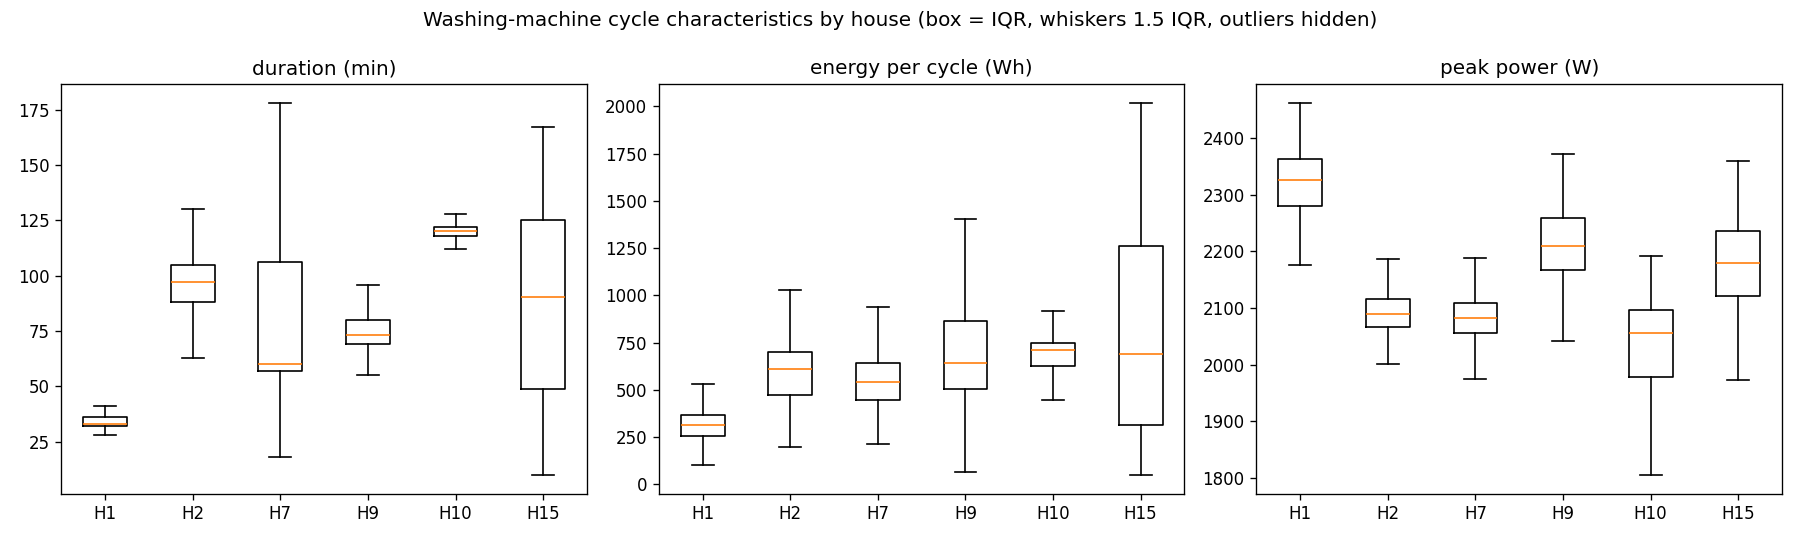

outputs/figures/eda_wm_sensitivity.png


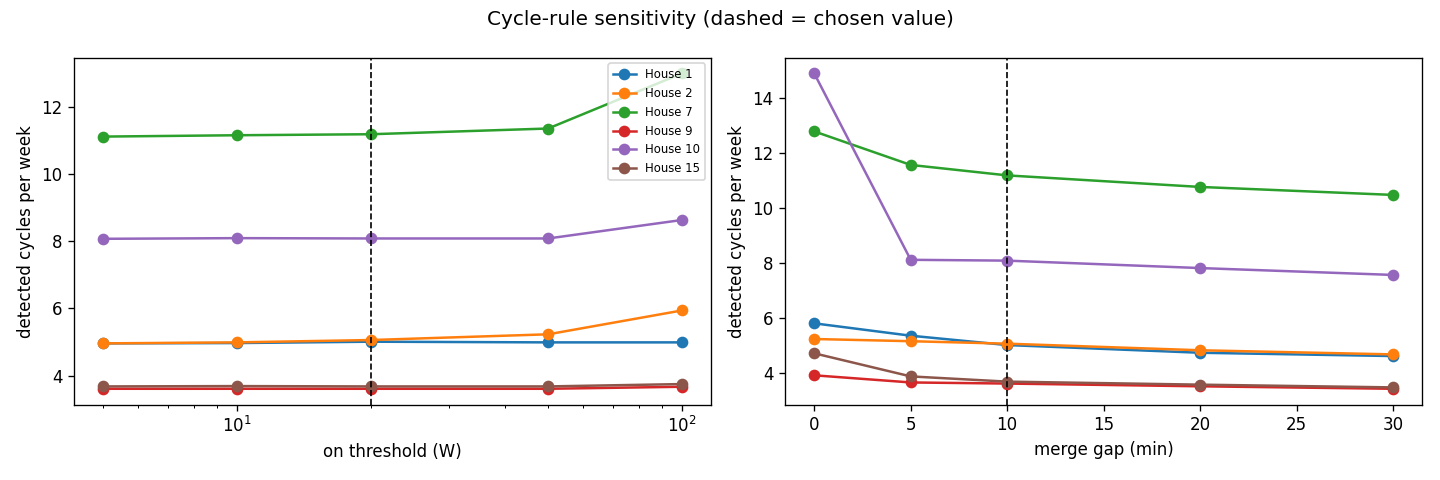

In [58]:
show_fig("eda_wm_cross_house")
show_fig("eda_wm_sensitivity")

### Seasonality
Washes per week stay within about 5–7 per house-week through the year, but the energy per wash is much
higher in winter: the heater runs longer to warm colder inlet water.

In [59]:
display_table("eda_wm_seasonality")

outputs/tables/eda_wm_seasonality.csv


,house,month,usable_days,cycles,cycles_per_week,median_energy_Wh,median_heater_min
0,1,1,53.4,46,6.03,NaN,NaN
1,1,2,28.0,22,5.50,NaN,NaN
2,1,3,51.6,26,3.52,NaN,NaN
3,1,4,54.8,43,5.50,NaN,NaN
4,1,5,51.1,30,4.11,NaN,NaN
...,...,...,...,...,...,...,...
79,pooled,8,184.0,151,5.74,422.60,10.0
80,pooled,9,186.9,172,6.44,547.65,12.0
81,pooled,10,224.9,186,5.79,549.70,12.0
82,pooled,11,232.0,221,6.67,591.20,14.0


outputs/figures/eda_wm_seasonality.png


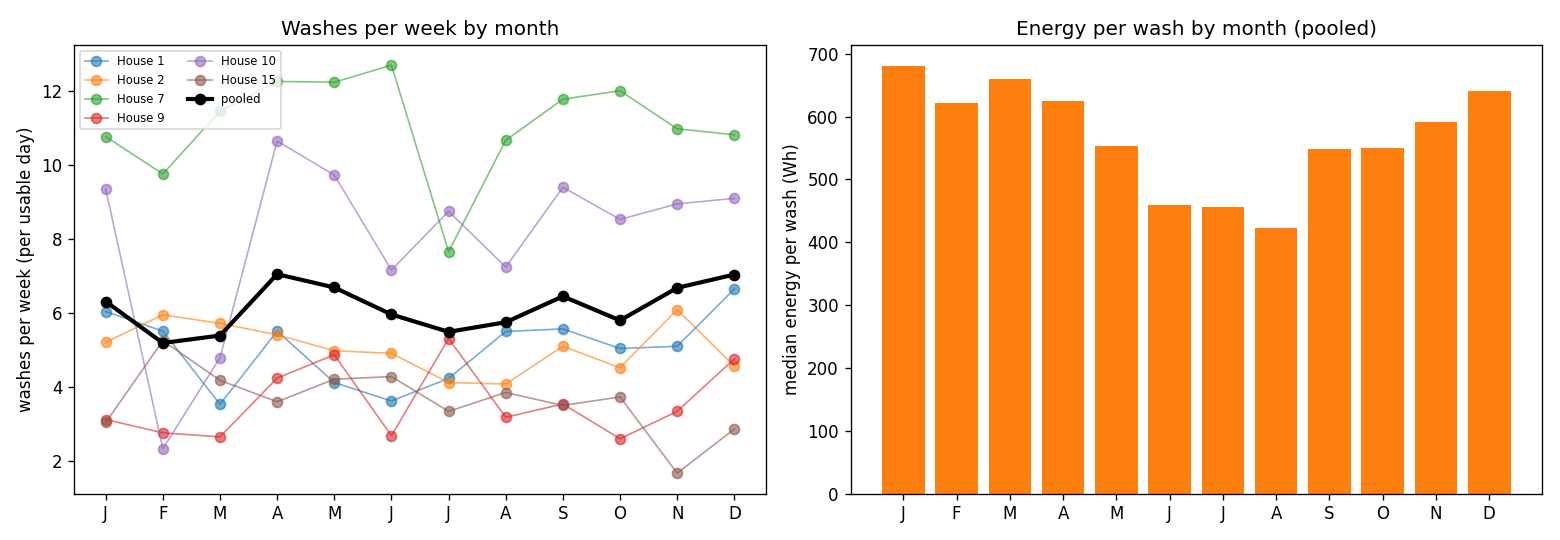

In [60]:
show_fig("eda_wm_seasonality")

### Wash programmes
Washes grouped into programme types by duration and heating minutes (P1 = shortest). The silhouette
table shows how the number of groups was chosen.

In [61]:
display_table("eda_wm_programme_k")
display_table("eda_wm_programmes")
display_table("eda_wm_programmes_by_house")

outputs/tables/eda_wm_programme_k.csv


,k,silhouette
0,2,0.475
1,3,0.482
2,4,0.506
3,5,0.511
4,6,0.470


outputs/tables/eda_wm_programmes.csv

,programme,washes,share_pct,median_duration_min,median_heater_min,median_energy_Wh,share_starting_weekday_peak_pct
0,P1,455,16.8,33.0,6.0,272.0,4.4
1,P2,954,35.3,60.0,12.0,493.0,15.0
2,P3,1112,41.1,116.0,16.0,705.0,22.2
3,P4,183,6.8,128.0,31.0,1283.0,15.3


outputs/tables/eda_wm_programmes_by_house.csv


,house,P1,P2,P3,P4
0,1,81.2,14.5,2.5,1.8
1,2,5.0,24.0,65.3,5.6
2,7,0.7,69.3,26.1,3.9
3,9,2.0,55.6,30.6,11.7
4,10,6.0,8.1,84.4,1.5
5,15,25.6,13.2,27.9,33.3


outputs/figures/eda_wm_programmes.png


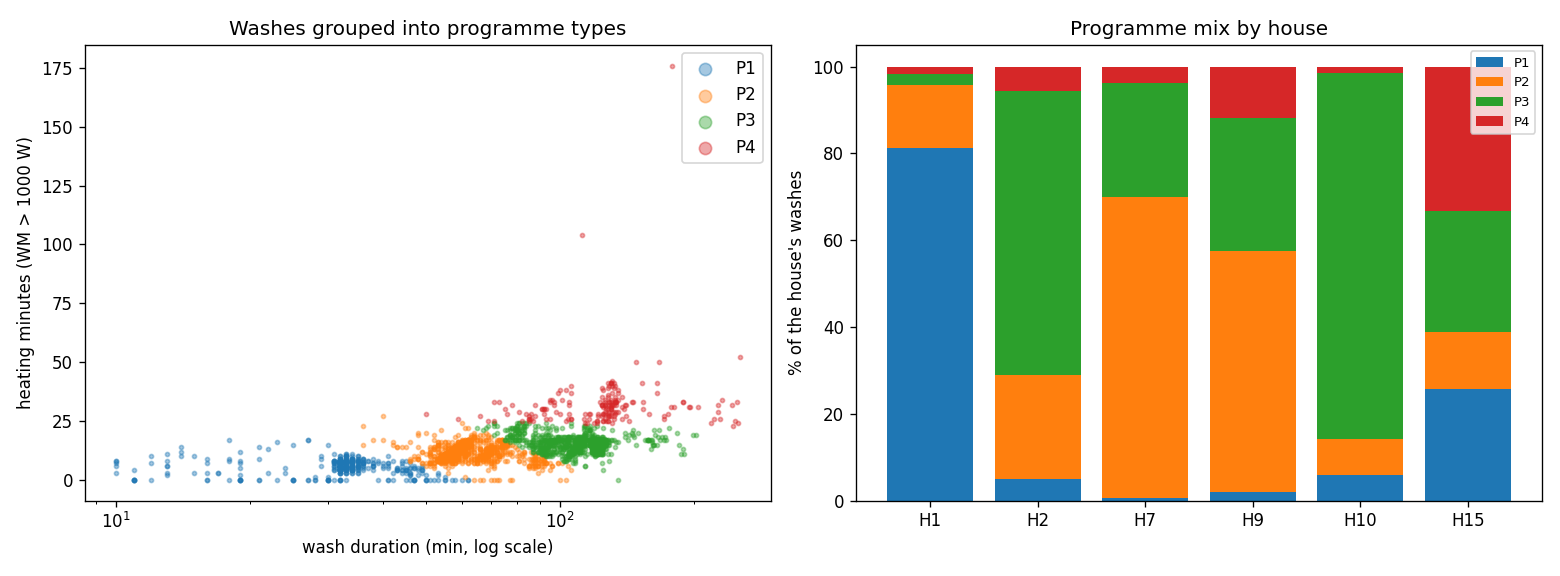

In [62]:
show_fig("eda_wm_programmes")

---
## 4. Disaggregation model: predictions and evaluation

**Task:** estimate washing-machine power (W) each minute from the household aggregate (1-minute data).

**Validation design, and why:**

| Role | Houses | Why |
|---|---|---|
| Train | 2, 7, 10, 15 (first 80 % of each record) | learn the patterns |
| Validation | 9 | choose the feature set, thresholds and final model, never the test houses |
| **Test (unseen houses)** | 8, 17 | the real use case: houses with no sub-metering |
| Time-split test | 2, 7, 10, 15, last 20 %, after a 1-day embargo | "same house, future months"; the embargo is longer than the ±60 min input window |

There is **no random shuffling of minutes**: neighbouring windows overlap almost completely, so a random split
would leak near-copies of test inputs into training.

**Inputs (Seq2Point idea, Zhang et al. 2018):** predict the WM at minute *t* from a window *t − 60 … t + 60*
of the aggregate, summarised as hand-made features (lags, differences, rolling statistics, heater-band share)
for LightGBM: fast, deterministic and easy to inspect.

**Models:** two baselines (always off; hour-of-day profile) and a **LightGBM regressor** that predicts WM power
directly. Its prediction is set to 0 below an on-threshold tuned on the validation house. **Cycle
post-processing** then keeps only predicted washes that pass the same cycle rule as the ground truth
(≥ 10 min, ≥ 50 Wh), removing short false blips. Whether to use the post-processing is decided on the
validation house by on/off F1, before the test houses are scored.

**Data filter:** where the aggregate is exactly flat for ≥ 60 min (a stuck, forward-filled sensor), it is set
to missing, so those minutes are neither inputs nor scored.

**Metrics:** MAE (W), total-energy error (%), daily-energy MAE (Wh/day), on/off precision/recall/F1 and
per-wash (cycle) precision/recall/F1. Pooled rows are computed from the houses' summed counts, so
pooled precision, recall and F1 stay consistent with each other.

In [63]:
ROLL_WINDOWS = [5, 15, 31, 61, 121]          # centred, minutes (121 = +-60)
SHIFTS = [1, 2, 3, 5, 10, 15, 30, 60]

In [64]:
# --------------------------------------------------------------- features
def make_features(df: pd.DataFrame) -> pd.DataFrame:
    a = df["aggregate"]
    f = pd.DataFrame(index=df.index)
    f["agg"] = a
    for k in SHIFTS:
        f[f"lag{k}"] = a.shift(k) - a
        f[f"lead{k}"] = a.shift(-k) - a
    d = a.diff()
    f["diff_prev"] = d
    f["diff_next"] = d.shift(-1)
    absd = d.abs()
    for w in ROLL_WINDOWS:
        r = a.rolling(w, center=True, min_periods=1)
        f[f"mean{w}"] = r.mean()
        f[f"std{w}"] = r.std()
        f[f"max{w}"] = r.max()
        f[f"min{w}"] = r.min()
        f[f"above_min{w}"] = a - f[f"min{w}"]
        f[f"absdiff_sum{w}"] = absd.rolling(w, center=True, min_periods=1).sum()
        f[f"maxstep{w}"] = d.rolling(w, center=True, min_periods=1).max()
        # minutes in window where load sits 1.5-2.6 kW above the window floor:
        # the WM heater signature
        heat = ((a - f[f"min{w}"]).between(1500, 2600)).astype(float)
        f[f"heat_frac{w}"] = heat.rolling(w, center=True, min_periods=1).mean()
    loc = df.index.tz_convert(C.LOCAL_TZ)
    hour = loc.hour + loc.minute / 60
    f["hour_sin"] = np.sin(2 * np.pi * hour / 24)
    f["hour_cos"] = np.cos(2 * np.pi * hour / 24)
    f["dow"] = loc.dayofweek
    f["weekend"] = (loc.dayofweek >= 5).astype(int)
    return f


TIME_FEATURES = ["hour_sin", "hour_cos", "dow", "weekend"]

In [65]:
def feature_sets(cols):
    """Candidate inputs. 'relative' drops absolute power levels (agg, rolling
    mean/max/min), keeping only shape: steps, spread, height above the local
    floor. Absolute level and clock time encode house-specific habits."""
    absolute = ["agg"] + [f"{s}{w}" for s in ("mean", "max", "min") for w in ROLL_WINDOWS]
    no_time = [c for c in cols if c not in TIME_FEATURES]
    return {"all": cols, "no_time": no_time,
            "relative": [c for c in no_time if c not in absolute]}

In [66]:
def cycle_filter(p: pd.Series, thr) -> pd.Series:
    """Zero predicted power outside predicted cycles that pass the cycle rule."""
    cyc = detect_cycles(p, on_w=thr)
    keep = np.zeros(len(p) + 1, np.int32)
    s = p.index.get_indexer(cyc["start"])
    np.add.at(keep, s, 1)
    np.add.at(keep, s + cyc["duration_min"].to_numpy(int), -1)
    return p.where(np.cumsum(keep)[:-1] > 0, 0.0)

In [67]:
def usable(df):
    return df["aggregate"].notna() & df["wm"].notna() & ~df["wm_gt_agg"]

In [68]:
def time_split(df):
    cut = df.index[int(len(df) * C.TIME_SPLIT_FRAC)]
    emb = cut + pd.Timedelta(days=C.EMBARGO_DAYS)
    return df.index < cut, df.index >= emb, cut

In [69]:
# ---------------------------------------------------------------- metrics
def onoff_scores(y, p, thr):
    t, q = y > C.WM_ON_W, p > thr
    tp = int((t & q).sum())
    prec = tp / max(int(q.sum()), 1)
    rec = tp / max(int(t.sum()), 1)
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return prec, rec, f1

In [70]:
def cycle_scores(y: pd.Series, p: pd.Series, thr):
    """Event-level: a true cycle is detected if any predicted cycle overlaps it."""
    tc = detect_cycles(y)
    pc = detect_cycles(p, on_w=thr)
    if len(tc) == 0 or len(pc) == 0:
        return len(tc), len(pc), 0, 0
    ts, te = tc["start"].values, tc["end"].values
    ps, pe = pc["start"].values, pc["end"].values
    hit_t = ((ps[None, :] < te[:, None]) & (pe[None, :] > ts[:, None])).any(axis=1)
    hit_p = ((ts[None, :] < pe[:, None]) & (te[None, :] > ps[:, None])).any(axis=1)
    return len(tc), len(pc), int(hit_t.sum()), int(hit_p.sum())

In [71]:
def prf(tp_true, n_true, tp_pred, n_pred):
    """Precision, recall, F1 from counts (true-side and predicted-side hits
    can differ for events, so both are passed)."""
    prec = tp_pred / n_pred if n_pred else 0.0
    rec = tp_true / n_true if n_true else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return prec, rec, f1

In [72]:
def score(name, split, house, y, p, thr):
    """y, p: Series on a regular minute grid (NaN = not evaluated)."""
    m = y.notna()
    yy, pp = y[m].to_numpy(), p[m].to_numpy()
    days = m.sum() / 1440
    true_kwh, pred_kwh = yy.sum() / 60000, pp.sum() / 60000
    dy = y[m].groupby(y[m].index.tz_convert(C.LOCAL_TZ).date).sum() / 60
    dp = p[m].groupby(p[m].index.tz_convert(C.LOCAL_TZ).date).sum() / 60
    t, q = yy > C.WM_ON_W, pp > thr
    on_tp, on_true, on_pred = int((t & q).sum()), int(t.sum()), int(q.sum())
    prec, rec, f1 = prf(on_tp, on_true, on_tp, on_pred)
    nt, npred, hit_t, hit_p = cycle_scores(y, p.where(m), thr)
    cprec, crec, cf1 = prf(hit_t, nt, hit_p, npred)
    abs_daily = (dy - dp).abs()
    return {
        "model": name, "split": split, "house": house, "eval_days": round(days, 1),
        "MAE_W": round(np.abs(yy - pp).mean(), 2),
        "RMSE_W": round(np.sqrt(((yy - pp) ** 2).mean()), 1),
        "true_kWh": round(true_kwh, 1), "pred_kWh": round(pred_kwh, 1),
        "energy_err_pct": round(100 * (pred_kwh - true_kwh) / true_kwh, 1),
        "daily_energy_MAE_Wh": round(abs_daily.mean(), 1),
        "on_threshold_W": thr,
        "onoff_precision": round(prec, 3), "onoff_recall": round(rec, 3),
        "onoff_F1": round(f1, 3),
        "true_cycles": nt, "pred_cycles": npred, "cycle_precision": round(cprec, 3),
        "cycle_recall": round(crec, 3), "cycle_F1": round(cf1, 3),
        # raw counts, so pooled rows are computed from totals, not averages
        "n_min": int(m.sum()), "abs_err_sum": float(np.abs(yy - pp).sum()),
        "true_kWh_raw": true_kwh, "pred_kWh_raw": pred_kwh,
        "n_days": len(abs_daily), "daily_abs_err_sum": float(abs_daily.sum()),
        "on_tp": on_tp, "on_true": on_true, "on_pred": on_pred,
        "cyc_true_hit": hit_t, "cyc_pred_hit": hit_p,
    }

In [73]:
# -------------------------------------------------------------- baselines
def hour_profile(train_frames):
    rows = []
    for df in train_frames:
        loc = df.index.tz_convert(C.LOCAL_TZ)
        rows.append(pd.DataFrame({"hour": loc.hour, "we": loc.dayofweek >= 5,
                                  "wm": df["wm"].to_numpy()}))
    return pd.concat(rows).groupby(["hour", "we"])["wm"].mean()

In [74]:
def apply_profile(profile, index):
    loc = index.tz_convert(C.LOCAL_TZ)
    key = pd.MultiIndex.from_arrays([loc.hour, loc.dayofweek >= 5])
    return pd.Series(profile.reindex(key).to_numpy(), index=index)

In [75]:
# ------------------------------------------------------------------ plots
def plot_actual_vs_pred(df, pred, house, path, days=3):
    """Window of `days` days starting on the test-house day whose true WM
    energy is closest to the 75th percentile of days with use."""
    wm = df["wm"]
    daily = wm.groupby(wm.index.tz_convert(C.LOCAL_TZ).normalize()).sum() / 60
    used = daily[daily > C.CYCLE_MIN_ENERGY_WH]
    start = (used - used.quantile(0.75)).abs().idxmin()
    a, b = start, start + pd.Timedelta(days=days)
    w = df.loc[a:b]
    pw = pred.loc[a:b]
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 7), sharex=True, height_ratios=[1, 1.3])
    ax1.plot(w.index, w["aggregate"], color="0.4", lw=0.7)
    ax1.set_ylabel("aggregate (W)")
    ax1.set_title(f"Test house {house} (never seen in training): actual vs predicted WM power")
    ax2.fill_between(w.index, 0, w["wm"], color="tab:blue", alpha=0.5, label="actual WM")
    ax2.plot(pw.index, pw.values, color="tab:red", lw=1, label="LightGBM prediction")
    ax2.set_ylabel("washing machine (W)")
    ax2.legend(loc="upper right")
    ax2.xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%a %d %b\n%H:%M", tz=C.LOCAL_TZ))
    fig.tight_layout()
    fig.savefig(path, dpi=120)
    plt.close(fig)

In [76]:
def plot_daily_energy(results, path):
    fig, axes = plt.subplots(1, len(results), figsize=(6 * len(results), 5))
    for ax, (h, (y, p)) in zip(np.atleast_1d(axes), results.items()):
        m = y.notna()
        key = y[m].index.tz_convert(C.LOCAL_TZ).date
        dy = y[m].groupby(key).sum() / 60
        dp = p[m].groupby(key).sum() / 60
        ax.scatter(dy, dp, s=8, alpha=0.5)
        lim = max(dy.max(), dp.max()) * 1.05
        ax.plot([0, lim], [0, lim], "k--", lw=1)
        ax.set_xlabel("actual WM energy per day (Wh)")
        ax.set_ylabel("predicted WM energy per day (Wh)")
        r = np.corrcoef(dy, dp)[0, 1]
        ax.set_title(f"Test house {h}: daily energy (r = {r:.2f}, n = {len(dy)} days)")
    fig.tight_layout()
    fig.savefig(path, dpi=120)
    plt.close(fig)

In [77]:
def plot_case(df, pred, a, b, title, path):
    w = df.loc[a:b]
    pw = pred.loc[a:b]
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
    ax1.plot(w.index, w["aggregate"], color="0.4", lw=0.8)
    ax1.set_ylabel("aggregate (W)")
    ax1.set_title(title)
    ax2.fill_between(w.index, 0, w["wm"], color="tab:blue", alpha=0.5, label="actual WM")
    ax2.plot(pw.index, pw.values, color="tab:red", lw=1, label="prediction")
    ax2.set_ylabel("washing machine (W)")
    ax2.legend(loc="upper right")
    ax2.xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%d %b %H:%M", tz=C.LOCAL_TZ))
    fig.tight_layout()
    fig.savefig(path, dpi=120)
    plt.close(fig)

In [78]:
def failure_cases(test_data, preds, thr):
    """(1) worst false-positive event, (2) worst missed true cycle."""
    fp_best, fn_best = None, None
    for h, df in test_data.items():
        p = preds[h]
        pc = detect_cycles(p, on_w=thr)
        if len(pc):
            true_wh = [df["wm"].loc[r.start:r.end].sum() / 60 for r in pc.itertuples()]
            pc = pc.assign(true_Wh=true_wh)
            cand = pc[pc["true_Wh"] < 10].sort_values("energy_Wh", ascending=False)
            if len(cand) and (fp_best is None or cand.iloc[0]["energy_Wh"] > fp_best[1]["energy_Wh"]):
                fp_best = (h, cand.iloc[0])
        tc = detect_cycles(df["wm"])
        if len(tc):
            frac = [p.loc[r.start:r.end].sum() / 60 / r.energy_Wh for r in tc.itertuples()]
            tc = tc.assign(pred_frac=frac)
            big = tc[tc["energy_Wh"] >= tc["energy_Wh"].median()].sort_values("pred_frac")
            if len(big) and (fn_best is None or big.iloc[0]["pred_frac"] < fn_best[1]["pred_frac"]):
                fn_best = (h, big.iloc[0])
    return fp_best, fn_best

In [79]:
# ------------------------------------------------------------------- main
def run_stage4_model():
    C.ensure_output_dirs()
    houses = C.TRAIN_HOUSES + C.VAL_HOUSES + C.TEST_HOUSES
    data = {h: load_house(h, local=False) for h in houses}
    excl = []
    for h, df in data.items():
        stuck = flat_minutes(df["aggregate"])
        excl.append({"house": h, "stuck_aggregate_min": int(stuck.sum()),
                     "stuck_pct": round(100 * stuck.mean(), 2),
                     "wm_gt_agg_min": int(df["wm_gt_agg"].sum())})
        df["aggregate"] = df["aggregate"].where(~stuck)
    pd.DataFrame(excl).to_csv(C.TAB_DIR / "model_excluded_minutes.csv", index=False)
    feats = {h: make_features(data[h]) for h in houses}
    fcols = list(next(iter(feats.values())).columns)

    # ---- training rows: first 80 % of each training house
    Xtr, ytr, tr_frames, cuts = [], [], [], {}
    for h in C.TRAIN_HOUSES:
        tr_mask, _, cut = time_split(data[h])
        cuts[h] = cut
        m = tr_mask & usable(data[h])
        Xtr.append(feats[h][m])
        ytr.append(data[h]["wm"][m])
        tr_frames.append(data[h][m])
    Xtr, ytr = pd.concat(Xtr), pd.concat(ytr)
    hv = C.VAL_HOUSES[0]
    mv = usable(data[hv])
    Xva, yva = feats[hv][mv], data[hv]["wm"][mv]
    print(f"train rows {len(Xtr):,}  val rows {len(Xva):,}  features {len(fcols)}", flush=True)

    # ---- feature-set selection on the validation house only.
    # The validation L2 curve is nearly flat after ~15 rounds, so early
    # stopping just picks an under-fitted model; we train a fixed number of
    # rounds and compare feature sets instead.
    sets = feature_sets(fcols)
    abl, fitted = [], {}
    for name, cols in sets.items():
        m = lgb.LGBMRegressor(random_state=C.RANDOM_SEED, deterministic=True, **C.LGBM_PARAMS)
        ev = {}
        m.fit(Xtr[cols], ytr, eval_X=(Xva[cols],), eval_y=(yva,), eval_metric="l2",
              callbacks=[lgb.record_evaluation(ev)])
        rmse = np.sqrt(np.array(ev["valid_0"]["l2"]))
        pv_ = np.clip(m.predict(Xva[cols]), 0, None)
        abl.append({"feature_set": name, "n_features": len(cols),
                    "val_RMSE_W_iter15": round(rmse[14], 1),
                    "val_RMSE_W_final": round(rmse[-1], 1),
                    "val_RMSE_W_always_off": round(float(np.sqrt((yva ** 2).mean())), 1),
                    "val_MAE_W": round(float(np.abs(pv_ - yva).mean()), 2),
                    "val_onoff_F1_at_30W": round(onoff_scores(yva.to_numpy(), pv_, 30)[2], 3)})
        fitted[name] = m
        print(abl[-1], flush=True)
    abl = pd.DataFrame(abl)
    chosen = abl.loc[abl["val_RMSE_W_final"].idxmin(), "feature_set"]
    abl["chosen"] = abl["feature_set"] == chosen
    abl.to_csv(C.TAB_DIR / "model_feature_set_selection.csv", index=False)
    model, fcols = fitted[chosen], sets[chosen]
    print("chosen feature set:", chosen, flush=True)

    profile = hour_profile(tr_frames)

    def predict(h, mask):
        idx = data[h].index
        out = {
            "always_off": pd.Series(0.0, index=idx),
            "hour_profile": apply_profile(profile, idx),
            "lgbm_raw": pd.Series(np.clip(model.predict(feats[h][fcols]), 0, None), index=idx),
        }
        y = data[h]["wm"].where(mask & usable(data[h]))
        return y, out

    # ---- tune on/off threshold per model on the validation house
    yv, pv = predict(hv, pd.Series(True, index=data[hv].index))
    tune_rows, best_thr = [], {}
    for name in ["hour_profile", "lgbm_raw"]:
        for thr in C.PRED_ON_GRID_W:
            pr, rc, f1 = onoff_scores(yv.dropna().to_numpy(), pv[name][yv.notna()].to_numpy(), thr)
            tune_rows.append({"model": name, "threshold_W": thr, "precision": round(pr, 3),
                              "recall": round(rc, 3), "F1": round(f1, 3)})
        t = pd.DataFrame(tune_rows)
        t = t[t["model"] == name]
        best_thr[name] = int(t.loc[t["F1"].idxmax(), "threshold_W"])
    best_thr["always_off"] = C.WM_ON_W
    best_thr["lgbm"] = best_thr["lgbm_cycles"] = best_thr["lgbm_raw"]
    pd.DataFrame(tune_rows).to_csv(C.TAB_DIR / "model_threshold_tuning.csv", index=False)
    print("tuned thresholds", best_thr, flush=True)

    def post_process(out):
        out["lgbm"] = out["lgbm_raw"].where(out["lgbm_raw"] > best_thr["lgbm"], 0.0)
        out["lgbm_cycles"] = cycle_filter(out["lgbm"], best_thr["lgbm"])
        return out

    # ---- evaluate
    rows, results = [], {}
    evals = [("validation", hv, pd.Series(True, index=data[hv].index))]
    evals += [("time_split_test", h, pd.Series(time_split(data[h])[1], index=data[h].index))
              for h in C.TRAIN_HOUSES]
    evals += [("house_test", h, pd.Series(True, index=data[h].index)) for h in C.TEST_HOUSES]
    for split, h, mask in evals:
        y, out = predict(h, mask)
        out = post_process(out)
        results[(split, h)] = (y, out)
        for name, p in out.items():
            rows.append(score(name, split, h, y, p, best_thr[name]))
    metrics = pd.DataFrame(rows)

    # ---- final model = post-processing variant with the better validation
    # on/off F1. (Cycle F1 cannot discriminate: cycle_scores already applies
    # the cycle rule to predictions, so the filter leaves it unchanged.)
    val = metrics[metrics["split"] == "validation"].set_index("model")
    final = "lgbm_cycles" if val.loc["lgbm_cycles", "onoff_F1"] > val.loc["lgbm", "onoff_F1"] \
        else "lgbm"
    val.loc[["lgbm", "lgbm_cycles"], ["onoff_F1", "cycle_F1", "energy_err_pct"]] \
        .assign(final=lambda d: d.index == final) \
        .to_csv(C.TAB_DIR / "model_final_choice.csv")
    print("final model:", final, flush=True)
    test_preds = {h: results[("house_test", h)][1][final] for h in C.TEST_HOUSES}
    saved = [pd.DataFrame({"house": h, "split": split, "wm_true": y, "wm_pred": out[final],
                           "aggregate": data[h]["aggregate"]})[y.notna()]
             for (split, h), (y, out) in results.items()]

    # pooled rows per split, computed from summed counts (not averages of
    # per-house ratios), so P, R and F1 stay mutually consistent
    pooled = []
    for (name, split), g in metrics.groupby(["model", "split"]):
        if g["house"].nunique() < 2:
            continue
        s = g.sum(numeric_only=True)
        tk, pk = s["true_kWh_raw"], s["pred_kWh_raw"]
        op, orc, of1 = prf(s["on_tp"], s["on_true"], s["on_tp"], s["on_pred"])
        cp, crc, cf1 = prf(s["cyc_true_hit"], s["true_cycles"], s["cyc_pred_hit"], s["pred_cycles"])
        pooled.append({
            "model": name, "split": split, "house": "pooled",
            "eval_days": round(s["n_min"] / 1440, 1),
            "MAE_W": round(s["abs_err_sum"] / s["n_min"], 2),
            "true_kWh": round(tk, 1), "pred_kWh": round(pk, 1),
            "energy_err_pct": round(100 * (pk - tk) / tk, 1),
            "daily_energy_MAE_Wh": round(s["daily_abs_err_sum"] / s["n_days"], 1),
            "on_threshold_W": g["on_threshold_W"].iloc[0],
            "onoff_precision": round(op, 3), "onoff_recall": round(orc, 3),
            "onoff_F1": round(of1, 3),
            "true_cycles": int(s["true_cycles"]), "pred_cycles": int(s["pred_cycles"]),
            "cycle_precision": round(cp, 3), "cycle_recall": round(crc, 3),
            "cycle_F1": round(cf1, 3),
        })
    metrics = pd.concat([metrics, pd.DataFrame(pooled)], ignore_index=True)
    metrics.to_csv(C.TAB_DIR / "model_metrics.csv", index=False)
    pd.concat(saved).to_parquet(C.CACHE_DIR / "model_predictions.parquet")

    split_info = pd.DataFrame(
        [{"house": h, "role": "train", "train_until": cuts[h],
          "time_test_from": cuts[h] + pd.Timedelta(days=C.EMBARGO_DAYS),
          "end": data[h].index[-1]} for h in C.TRAIN_HOUSES]
        + [{"house": hv, "role": "validation", "end": data[hv].index[-1]}]
        + [{"house": h, "role": "test", "end": data[h].index[-1]} for h in C.TEST_HOUSES])
    split_info.to_csv(C.TAB_DIR / "model_split.csv", index=False)

    imp = pd.DataFrame({"feature": fcols,
                        "gain": model.booster_.feature_importance("gain")})
    imp["gain_pct"] = (100 * imp["gain"] / imp["gain"].sum()).round(2)
    imp = imp.sort_values("gain", ascending=False)
    imp.to_csv(C.TAB_DIR / "model_feature_importance.csv", index=False)
    fig, ax = plt.subplots(figsize=(8, 6))
    top = imp.head(20)[::-1]
    ax.barh(top["feature"], top["gain_pct"])
    ax.set_xlabel("% of total gain")
    ax.set_title("LightGBM top-20 features")
    fig.tight_layout()
    fig.savefig(C.FIG_DIR / "model_feature_importance.png", dpi=120)
    plt.close(fig)

    # ---- plots on test houses
    ht = C.TEST_HOUSES[0]
    plot_actual_vs_pred(data[ht], test_preds[ht], ht, C.FIG_DIR / "model_actual_vs_pred.png")
    plot_daily_energy({h: (data[h]["wm"].where(usable(data[h])), test_preds[h])
                       for h in C.TEST_HOUSES}, C.FIG_DIR / "model_daily_energy_test.png")
    # search failure cases only among evaluated minutes (WM > aggregate excluded)
    scored = {h: data[h].assign(wm=data[h]["wm"].where(usable(data[h]))) for h in C.TEST_HOUSES}
    fp, fn = failure_cases(scored, test_preds, best_thr["lgbm"])
    cases = []
    if fp is not None:
        h, r = fp
        pad = pd.Timedelta(hours=2)
        plot_case(data[h], test_preds[h], r["start"] - pad, r["end"] + pad,
                  f"Failure 1 - false positive, house {h}: model predicts "
                  f"{r['energy_Wh']:.0f} Wh of WM use, actual {r['true_Wh']:.0f} Wh",
                  C.FIG_DIR / "model_failure_false_positive.png")
        cases.append({"case": "false_positive", "house": h, "start": r["start"],
                      "end": r["end"], "pred_Wh": r["energy_Wh"], "true_Wh": r["true_Wh"]})
    if fn is not None:
        h, r = fn
        pad = pd.Timedelta(hours=2)
        plot_case(data[h], test_preds[h], r["start"] - pad, r["end"] + pad,
                  f"Failure 2 - missed cycle, house {h}: actual {r['energy_Wh']:.0f} Wh, "
                  f"predicted {100 * r['pred_frac']:.0f} % of it",
                  C.FIG_DIR / "model_failure_missed_cycle.png")
        cases.append({"case": "missed_cycle", "house": h, "start": r["start"],
                      "end": r["end"], "pred_Wh": r["pred_frac"] * r["energy_Wh"],
                      "true_Wh": r["energy_Wh"]})
    pd.DataFrame(cases).to_csv(C.TAB_DIR / "model_failure_cases.csv", index=False)

    pd.set_option("display.width", 250, "display.max_columns", 30)
    show = ["model", "split", "house", "eval_days", "MAE_W", "energy_err_pct",
            "daily_energy_MAE_Wh", "onoff_precision", "onoff_recall", "onoff_F1",
            "true_cycles", "pred_cycles", "cycle_precision", "cycle_recall", "cycle_F1"]
    print(metrics[show].sort_values(["split", "house", "model"]).to_string(index=False))
    print(imp.head(10).to_string(index=False))
    print(pd.DataFrame(cases).to_string(index=False))

**Run stage 4** (≈ 8 min): build features, select the feature set, train, tune on validation, predict and score every split.

In [80]:
t = time.time()
run_stage4_model()
print(f'stage 4 done in {time.time() - t:.0f} s')

train rows 2,286,286  val rows 654,281  features 63


{'feature_set': 'all', 'n_features': 63, 'val_RMSE_W_iter15': 149.5, 'val_RMSE_W_final': 151.2, 'val_RMSE_W_always_off': 166.7, 'val_MAE_W': 28.43, 'val_onoff_F1_at_30W': 0.373}


{'feature_set': 'no_time', 'n_features': 59, 'val_RMSE_W_iter15': 150.2, 'val_RMSE_W_final': 150.6, 'val_RMSE_W_always_off': 166.7, 'val_MAE_W': 27.52, 'val_onoff_F1_at_30W': 0.384}


{'feature_set': 'relative', 'n_features': 43, 'val_RMSE_W_iter15': 149.3, 'val_RMSE_W_final': 149.8, 'val_RMSE_W_always_off': 166.7, 'val_MAE_W': 26.97, 'val_onoff_F1_at_30W': 0.388}


chosen feature set: relative


tuned thresholds {'hour_profile': 30, 'lgbm_raw': 50, 'always_off': 20, 'lgbm': 50, 'lgbm_cycles': 50}


final model: lgbm_cycles


       model           split  house  eval_days  MAE_W  energy_err_pct  daily_energy_MAE_Wh  onoff_precision  onoff_recall  onoff_F1  true_cycles  pred_cycles  cycle_precision  cycle_recall  cycle_F1
  always_off      house_test      8      493.0  29.31          -100.0                677.2            0.000         0.000     0.000          369            0            0.000         0.000     0.000
hour_profile      house_test      8      493.0  54.38            -9.3                616.5            0.028         0.365     0.053          369         1358            0.102         0.401     0.163
        lgbm      house_test      8      493.0  34.17           -10.7                404.3            0.345         0.766     0.475          369         1164            0.309         0.962     0.468
 lgbm_cycles      house_test      8      493.0  31.57           -20.1                403.8            0.480         0.745     0.584          369         1164            0.309         0.962     0.468
    l

stage 4 done in 233 s


### Choices made on the validation house

In [81]:
display_table("model_split")
display_table("model_excluded_minutes")
display_table("model_feature_set_selection")
display_table("model_final_choice")

outputs/tables/model_split.csv


,house,role,train_until,time_test_from,end
0,2,train,2015-01-24 20:30:00+00:00,2015-01-25 20:30:00+00:00,2015-05-28 08:05:00+00:00
1,7,train,2015-03-07 10:57:00+00:00,2015-03-08 10:57:00+00:00,2015-07-08 02:10:00+00:00
2,10,train,2015-03-05 01:36:00+00:00,2015-03-06 01:36:00+00:00,2015-06-30 11:07:00+00:00
3,15,train,2015-03-16 14:49:00+00:00,2015-03-17 14:49:00+00:00,2015-07-08 02:10:00+00:00
4,9,validation,NaN,NaN,2015-07-08 18:52:00+00:00
5,8,test,NaN,NaN,2015-05-10 23:36:00+00:00
6,17,test,NaN,NaN,2015-06-19 14:52:00+00:00


outputs/tables/model_excluded_minutes.csv


,house,stuck_aggregate_min,stuck_pct,wm_gt_agg_min
0,2,6581,0.74,113
1,7,5067,0.57,594
2,10,67523,7.99,222
3,15,6632,0.81,356
4,9,38665,4.73,35
5,8,8101,1.01,138
6,17,14612,2.16,393


outputs/tables/model_feature_set_selection.csv


,feature_set,n_features,val_RMSE_W_iter15,val_RMSE_W_final,val_RMSE_W_always_off,val_MAE_W,val_onoff_F1_at_30W,chosen
0,all,63,149.5,151.2,166.7,28.43,0.373,False
1,no_time,59,150.2,150.6,166.7,27.52,0.384,False
2,relative,43,149.3,149.8,166.7,26.97,0.388,True


outputs/tables/model_final_choice.csv


,model,onoff_F1,cycle_F1,energy_err_pct,final
0,lgbm,0.399,0.408,46.2,False
1,lgbm_cycles,0.468,0.408,32.4,True


In [82]:
display_table("model_threshold_tuning")

outputs/tables/model_threshold_tuning.csv


,model,threshold_W,precision,recall,F1
0,hour_profile,10,0.040,0.884,0.077
1,hour_profile,20,0.040,0.861,0.076
2,hour_profile,30,0.044,0.660,0.082
3,hour_profile,50,0.040,0.217,0.067
4,hour_profile,75,0.019,0.020,0.020
5,hour_profile,100,0.000,0.000,0.000
6,hour_profile,150,0.000,0.000,0.000
7,hour_profile,200,0.000,0.000,0.000
8,lgbm_raw,10,0.179,0.939,0.301
9,lgbm_raw,20,0.225,0.891,0.359


### Model predictions
Minute-level predictions of the final model for every evaluated minute (validation, time-split test and
unseen test houses), saved to `data/cache/model_predictions.parquet`. Below: a sample of minutes where the
washing machine was on in test house 8, and the predicted vs true energy per house and split.

In [83]:
pred = pd.read_parquet(C.CACHE_DIR / "model_predictions.parquet")
print(f"{len(pred):,} predicted minutes")
on = pred[(pred["house"] == 8) & (pred["wm_true"] > C.WM_ON_W)]
display(on.head(15).round(1))

energy = (pred.groupby(["split", "house"])[["wm_true", "wm_pred"]].sum() / 60 / 1000).round(1)
energy.columns = ["true_kWh", "pred_kWh"]
energy["error_pct"] = (100 * (energy["pred_kWh"] - energy["true_kWh"]) / energy["true_kWh"]).round(1)
display(energy)

2,509,483 predicted minutes


,house,split,wm_true,wm_pred,aggregate
Unix,,,,,
2013-11-02 03:23:00+00:00,8,house_test,77.4,57.1,280.3
2013-11-02 03:24:00+00:00,8,house_test,411.0,248.0,694.5
2013-11-02 03:25:00+00:00,8,house_test,2366.6,1583.7,2618.6
2013-11-02 03:26:00+00:00,8,house_test,2276.1,1620.3,2712.2
2013-11-02 03:27:00+00:00,8,house_test,2350.9,1724.0,2536.1
2013-11-02 03:28:00+00:00,8,house_test,2293.7,1784.9,2637.8
2013-11-02 03:29:00+00:00,8,house_test,2289.0,2039.8,2629.3
2013-11-02 03:30:00+00:00,8,house_test,2305.6,2019.5,2697.7
2013-11-02 03:31:00+00:00,8,house_test,2367.2,2042.3,2680.1


true_kWh  pred_kWh  error_pct
split           house                               
house_test      8         346.7     277.0      -20.1
                17        103.9      88.6      -14.7
time_split_test 2          50.7      52.6        3.7
                7         101.6      84.4      -16.9
                10         63.9      50.5      -21.0
                15         34.8      29.2      -16.1
validation      9         172.8     228.8       32.4

### Evaluation: all models, all splits
`lgbm` is the LightGBM regressor with the tuned on-threshold, `lgbm_cycles` the same with cycle
post-processing; the final choice is in `model_final_choice.csv` above. The baselines show what can be done
without disaggregation.

In [84]:
m = pd.read_csv(C.TAB_DIR / "model_metrics.csv")
cols = ["model", "split", "house", "eval_days", "MAE_W", "energy_err_pct", "daily_energy_MAE_Wh",
        "onoff_precision", "onoff_recall", "onoff_F1", "true_cycles", "pred_cycles",
        "cycle_precision", "cycle_recall", "cycle_F1"]
keep = ["always_off", "hour_profile", "lgbm", "lgbm_cycles"]
for split in ["house_test", "time_split_test", "validation"]:
    print(split)
    display(m[(m["split"] == split) & m["model"].isin(keep)][cols]
            .sort_values(["house", "model"], key=lambda s: s.astype(str)))

house_test


,model,split,house,eval_days,MAE_W,energy_err_pct,daily_energy_MAE_Wh,onoff_precision,onoff_recall,onoff_F1,true_cycles,pred_cycles,cycle_precision,cycle_recall,cycle_F1
30,always_off,house_test,17,431.0,10.05,-100.0,232.5,0.000,0.000,0.000,288,0,0.000,0.000,0.000
31,hour_profile,house_test,17,431.0,34.72,164.8,445.2,0.038,0.685,0.072,288,1229,0.156,0.733,0.258
33,lgbm,house_test,17,431.0,9.69,-1.2,127.0,0.454,0.663,0.539,288,453,0.530,0.830,0.647
34,lgbm_cycles,house_test,17,431.0,8.66,-14.7,123.4,0.587,0.591,0.589,288,453,0.530,0.830,0.647
25,always_off,house_test,8,493.0,29.31,-100.0,677.2,0.000,0.000,0.000,369,0,0.000,0.000,0.000
26,hour_profile,house_test,8,493.0,54.38,-9.3,616.5,0.028,0.365,0.053,369,1358,0.102,0.401,0.163
28,lgbm,house_test,8,493.0,34.17,-10.7,404.3,0.345,0.766,0.475,369,1164,0.309,0.962,0.468
29,lgbm_cycles,house_test,8,493.0,31.57,-20.1,403.8,0.480,0.745,0.584,369,1164,0.309,0.962,0.468
35,always_off,house_test,pooled,924.0,20.32,-100.0,469.9,0.000,0.000,0.000,657,0,0.000,0.000,0.000
37,hour_profile,house_test,pooled,924.0,45.21,30.9,536.7,0.033,0.488,0.062,657,2587,0.128,0.546,0.207


time_split_test


,model,split,house,eval_days,MAE_W,energy_err_pct,daily_energy_MAE_Wh,onoff_precision,onoff_recall,onoff_F1,true_cycles,pred_cycles,cycle_precision,cycle_recall,cycle_F1
15,always_off,time_split_test,10,79.2,33.63,-100.0,717.9,0.000,0.000,0.000,104,0,0.000,0.000,0.000
16,hour_profile,time_split_test,10,79.2,53.43,-21.1,510.4,0.130,0.601,0.213,104,224,0.304,0.750,0.432
18,lgbm,time_split_test,10,79.2,29.05,-6.5,279.1,0.429,0.570,0.489,104,216,0.472,0.885,0.616
19,lgbm_cycles,time_split_test,10,79.2,25.07,-21.0,256.2,0.645,0.508,0.569,104,216,0.472,0.885,0.616
20,always_off,time_split_test,15,88.0,16.50,-100.0,362.9,0.000,0.000,0.000,47,0,0.000,0.000,0.000
21,hour_profile,time_split_test,15,88.0,41.46,60.6,542.8,0.027,0.395,0.051,47,240,0.087,0.468,0.147
23,lgbm,time_split_test,15,88.0,4.34,-14.9,62.7,0.886,0.755,0.815,47,48,0.917,0.915,0.916
24,lgbm_cycles,time_split_test,15,88.0,4.23,-16.1,62.0,0.936,0.747,0.831,47,48,0.917,0.915,0.916
5,always_off,time_split_test,2,105.0,20.13,-100.0,449.0,0.000,0.000,0.000,87,0,0.000,0.000,0.000
6,hour_profile,time_split_test,2,105.0,43.03,31.2,467.6,0.073,0.643,0.132,87,290,0.203,0.782,0.323


validation


,model,split,house,eval_days,MAE_W,energy_err_pct,daily_energy_MAE_Wh,onoff_precision,onoff_recall,onoff_F1,true_cycles,pred_cycles,cycle_precision,cycle_recall,cycle_F1
0,always_off,validation,9,454.4,15.84,-100.0,365.3,0.000,0.000,0.000,256,0,0.000,0.000,0.000
1,hour_profile,validation,9,454.4,40.17,67.7,571.5,0.044,0.660,0.082,256,1258,0.135,0.758,0.229
3,lgbm,validation,9,454.4,24.95,46.2,335.9,0.285,0.666,0.399,256,1036,0.259,0.961,0.408
4,lgbm_cycles,validation,9,454.4,22.92,32.4,314.4,0.371,0.635,0.468,256,1036,0.259,0.961,0.408


### Actual vs predicted, daily energy, and what the model looks at

outputs/figures/model_actual_vs_pred.png


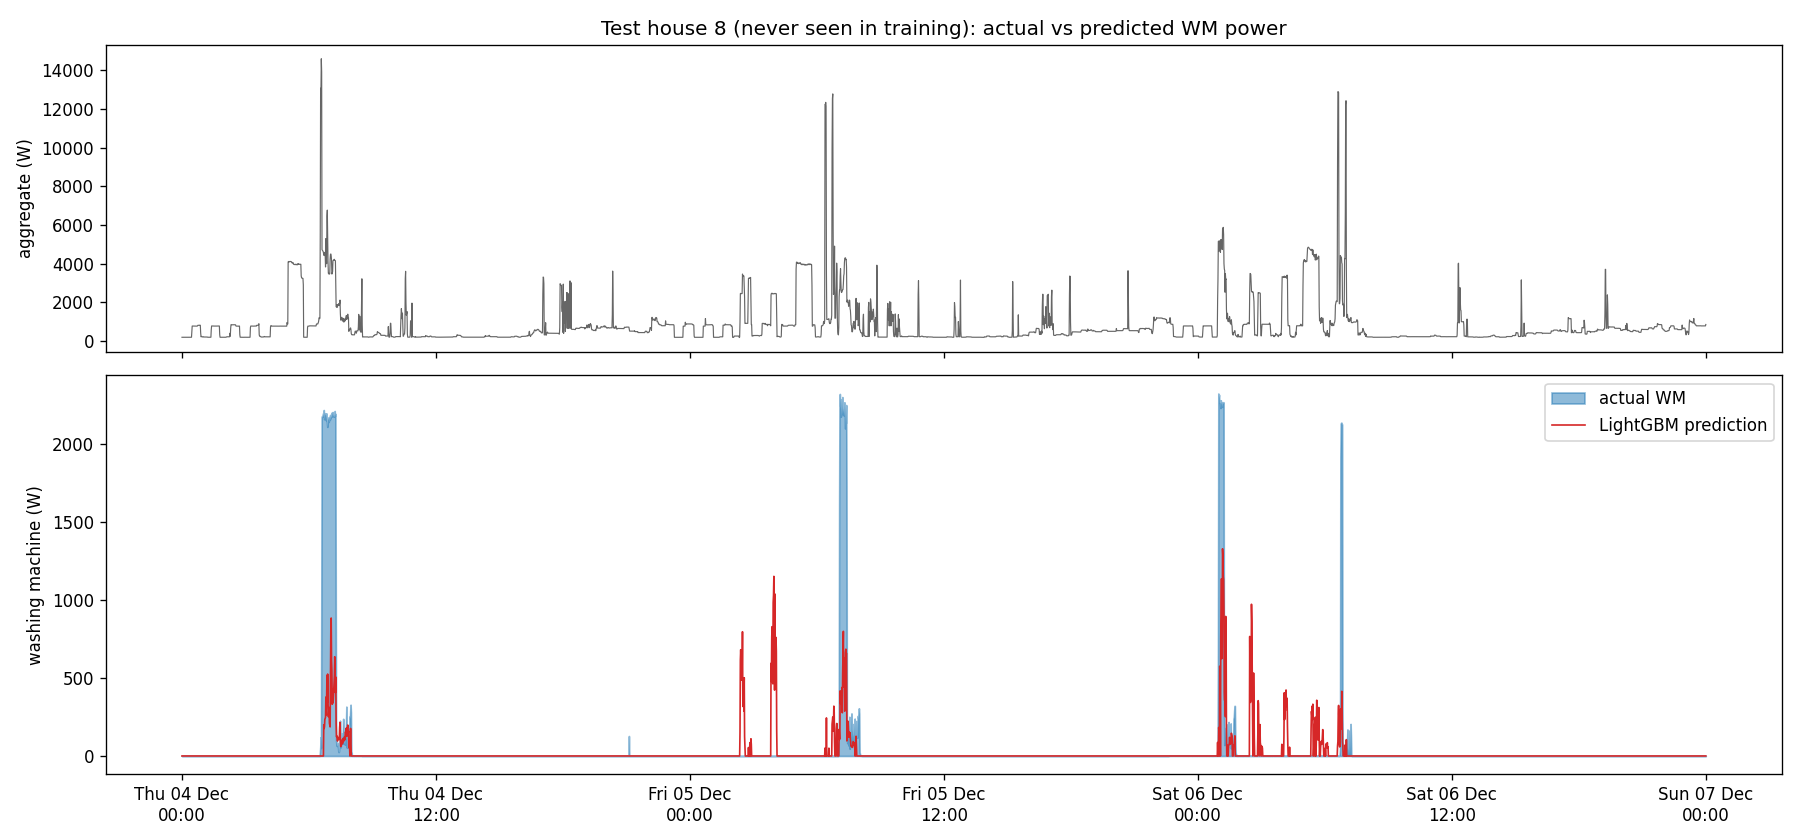

outputs/figures/model_daily_energy_test.png


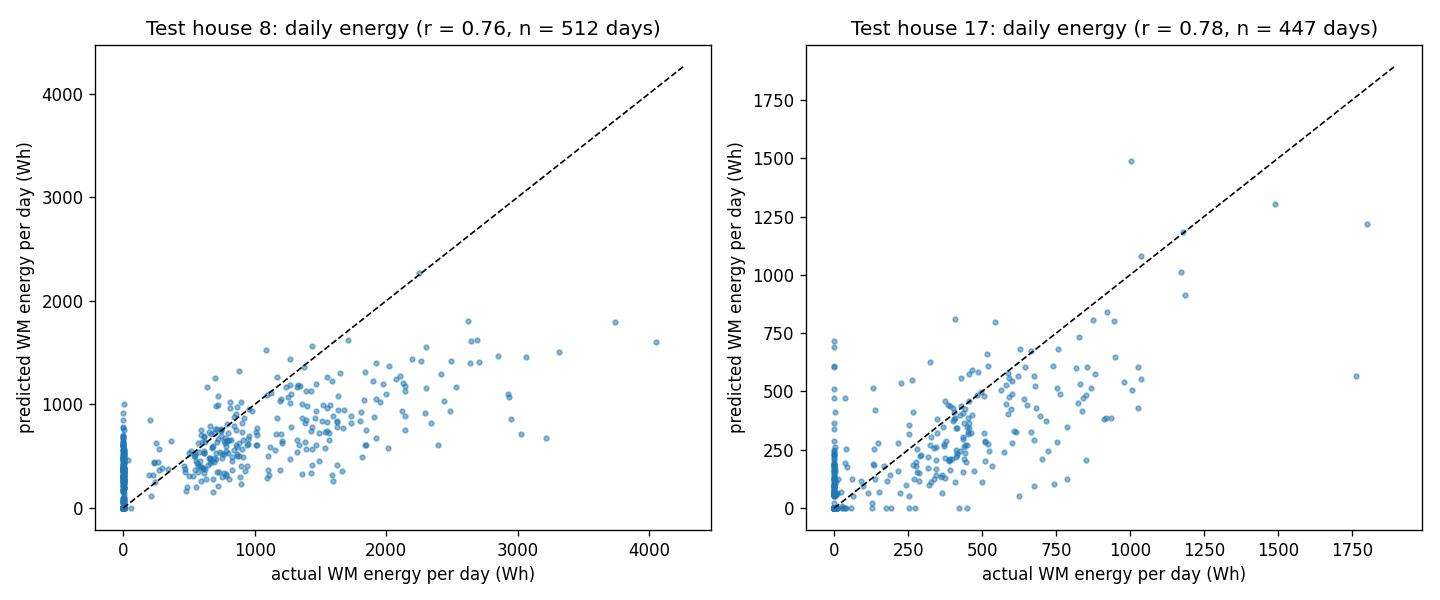

outputs/figures/model_feature_importance.png


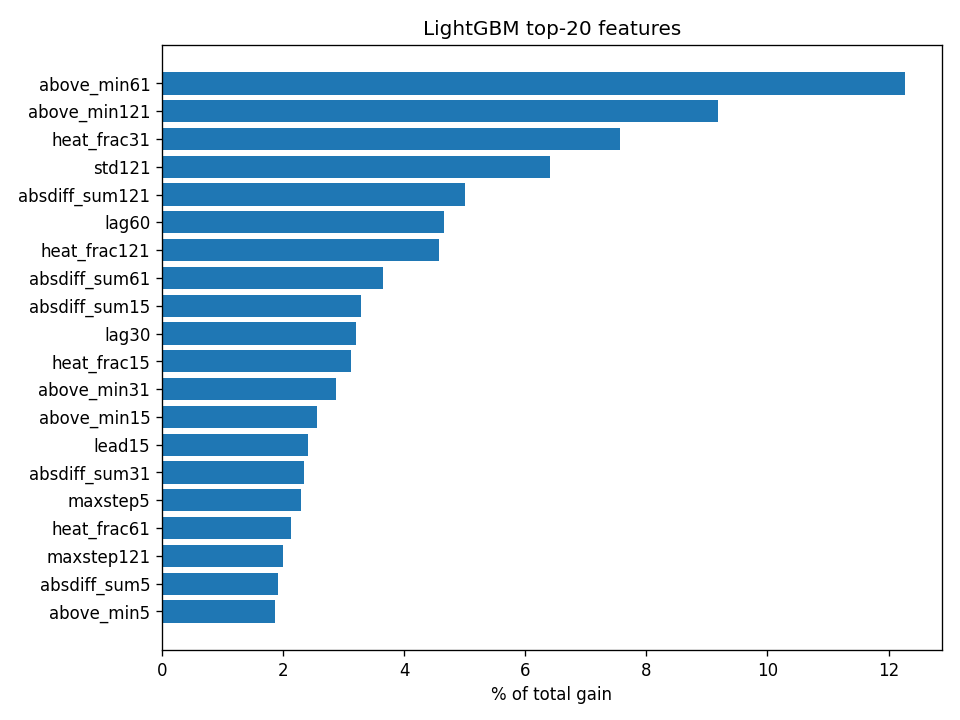

In [85]:
show_fig("model_actual_vs_pred")
show_fig("model_daily_energy_test")
show_fig("model_feature_importance")

In [86]:
display_table("model_feature_importance", n=15)

outputs/tables/model_feature_importance.csv


,feature,gain,gain_pct
0,above_min61,7.921309e+10,12.27
1,above_min121,5.923477e+10,9.18
2,heat_frac31,4.881486e+10,7.56
3,std121,4.140488e+10,6.41
4,absdiff_sum121,3.237031e+10,5.01
5,lag60,3.000148e+10,4.65
6,heat_frac121,2.958375e+10,4.58
7,absdiff_sum61,2.354312e+10,3.65
8,absdiff_sum15,2.124821e+10,3.29
9,lag30,2.070246e+10,3.21


### Failure cases
Chosen automatically on the test houses: (1) the predicted wash with the most energy where the true WM
use was (almost) zero, a **false positive**; (2) the largest true wash the model **missed** almost entirely.
Typical causes are other loads with a ~2 kW step (cooking, heaters) and washes hidden under big loads such as
an electric shower.

In [87]:
display_table("model_failure_cases")

outputs/tables/model_failure_cases.csv


,case,house,start,end,pred_Wh,true_Wh
0,false_positive,8,2014-01-03 01:43:00+00:00,2014-01-03 03:08:00+00:00,732.4,0.0
1,missed_cycle,8,2014-05-07 05:28:00+00:00,2014-05-07 06:35:00+00:00,0.0,1113.8


outputs/figures/model_failure_false_positive.png


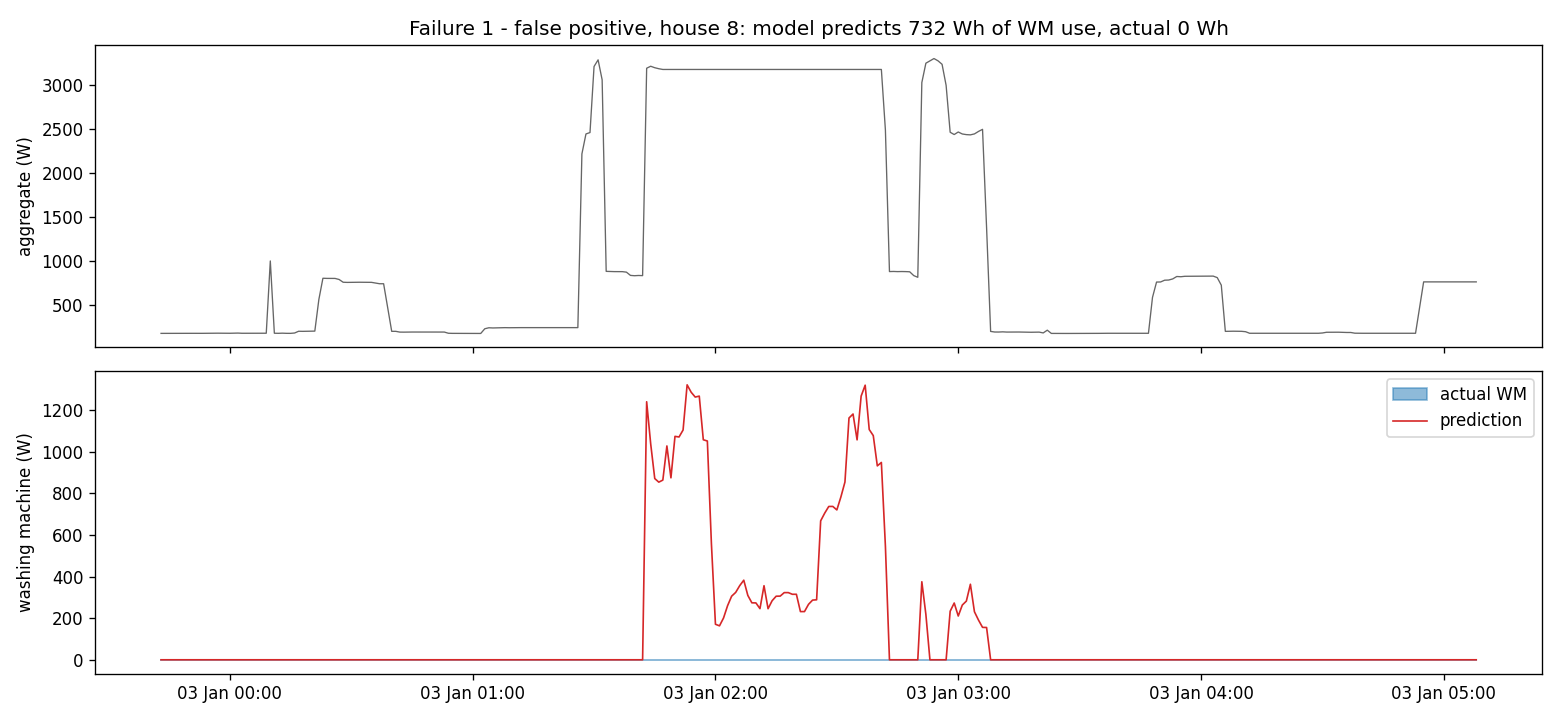

outputs/figures/model_failure_missed_cycle.png


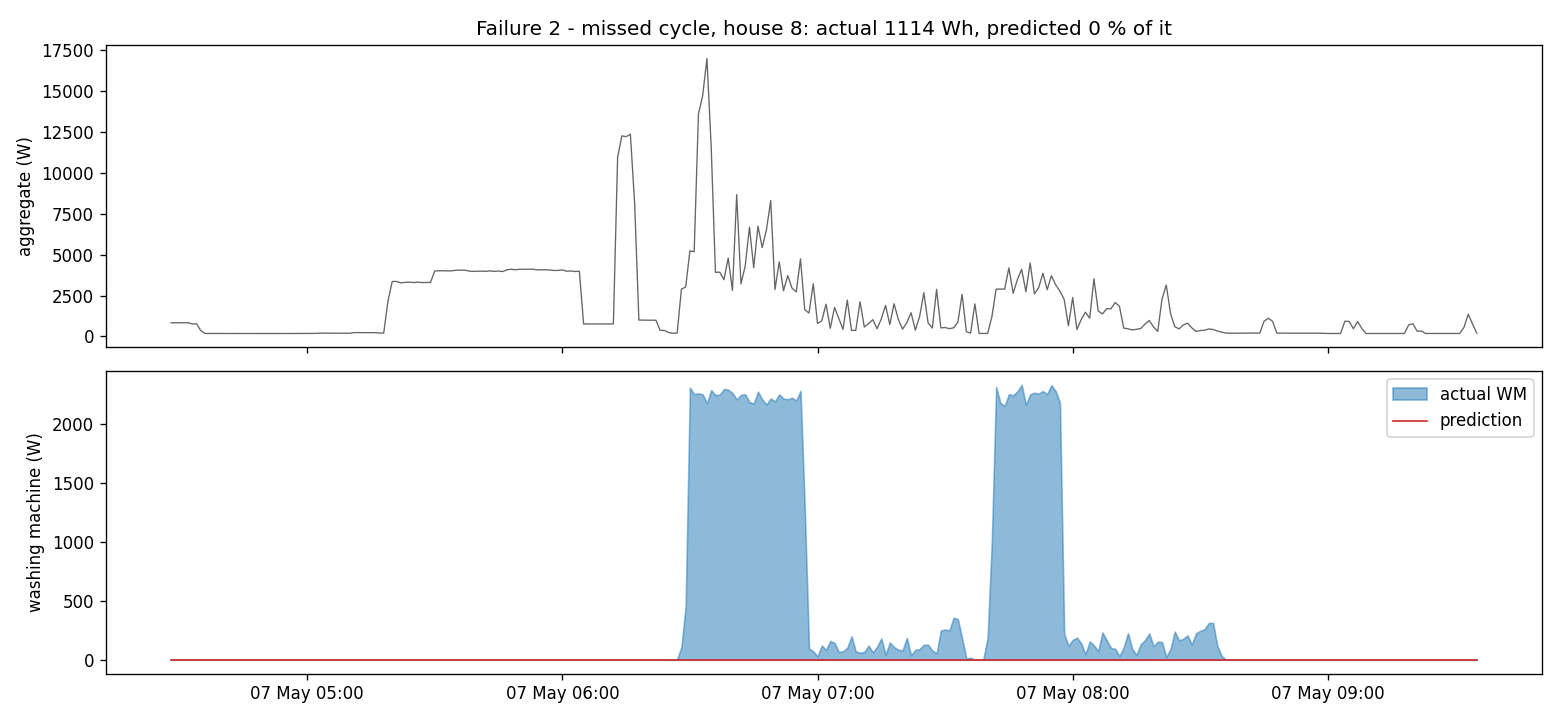

In [88]:
show_fig("model_failure_false_positive")
show_fig("model_failure_missed_cycle")

In [89]:
print(f'whole notebook finished in {(time.time() - T0) / 60:.1f} min')

whole notebook finished in 7.4 min
